# 01 EDA 分析：从客户特征理解严重逾期风险

本项目的坏客户指 `SeriousDlqin2yrs=1`，即未来两年发生严重逾期。本 Notebook 只分析从有标签原始文件分层划分得到的训练集。描述性分组用于观察风险，不是正式 WOE 分箱。

先在项目根目录运行 `python -m src.data_processing.run_stage2`，生成所有图表和结果。

In [1]:
from pathlib import Path
import sys
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data_processing.schema import load_labeled_training
from src.data_processing.split import stratified_split
from src.data_processing.analysis import analyze_training
from src.data_processing.narratives import build_narratives

data, source = load_labeled_training(ROOT / 'data' / 'raw')
splits = stratified_split(data)
eda = analyze_training(splits.train)
narratives = build_narratives(eda, min(500, len(splits.train)))
print(f'数据来源：{source.name}；训练集：{len(splits.train):,} 条')
display(eda.overview, eda.quality, eda.anomalies)

数据来源：GiveMeSomeCredit-training.csv；训练集：105,000 条


,sample_count,feature_count,good_count,bad_count,bad_rate,duplicate_rows
0,105000,10,97982,7018,0.066838,351


,feature,dtype,missing_count,missing_rate,zero_count,min,p01,median,p99,max
0,RevolvingUtilizationOfUnsecuredLines,float64,0,0.000000,7688,0.0,0.0,0.153553,1.095308,50708.0
1,age,int64,0,0.000000,0,21.0,24.0,52.000000,87.000000,109.0
2,NumberOfTime30-59DaysPastDueNotWorse,int64,0,0.000000,88178,0.0,0.0,0.000000,4.000000,98.0
3,DebtRatio,float64,0,0.000000,2908,0.0,0.0,0.367554,4977.020000,329664.0
4,MonthlyIncome,float64,20723,0.197362,1146,0.0,0.0,5382.000000,25000.000000,1794060.0
5,NumberOfOpenCreditLinesAndLoans,int64,0,0.000000,1321,0.0,0.0,8.000000,25.000000,58.0
6,NumberOfTimes90DaysLate,int64,0,0.000000,99103,0.0,0.0,0.000000,3.000000,98.0
7,NumberRealEstateLoansOrLines,int64,0,0.000000,39193,0.0,0.0,1.000000,4.000000,54.0
8,NumberOfTime60-89DaysPastDueNotWorse,int64,0,0.000000,99662,0.0,0.0,0.000000,2.000000,98.0
9,NumberOfDependents,float64,2721,0.025914,60782,0.0,0.0,0.000000,4.000000,13.0


,issue,row_count,row_rate,bad_rate,handling
0,年龄为零或负值,0,0.000000,NaN,无效年龄，单独标记并用训练集中位数填补
1,逾期字段出现96/98,182,0.001733,0.543956,特殊编码，保留标记后填补
2,额度使用率大于1,2322,0.022114,0.370801,可能有业务含义，第二阶段保留原值
3,债务比率大于1,24499,0.233324,0.063962,结合收入和字段定义解读，第二阶段保留原值
4,月收入为零,1146,0.010914,0.040140,与缺失区分，第二阶段保留原值


## 一、数据质量与原始分布

缺失率 = 缺失条数 ÷ 训练集样本数。分布图只截取横轴至 99 分位以方便阅读，原始数值未被截断。

### missing_rate

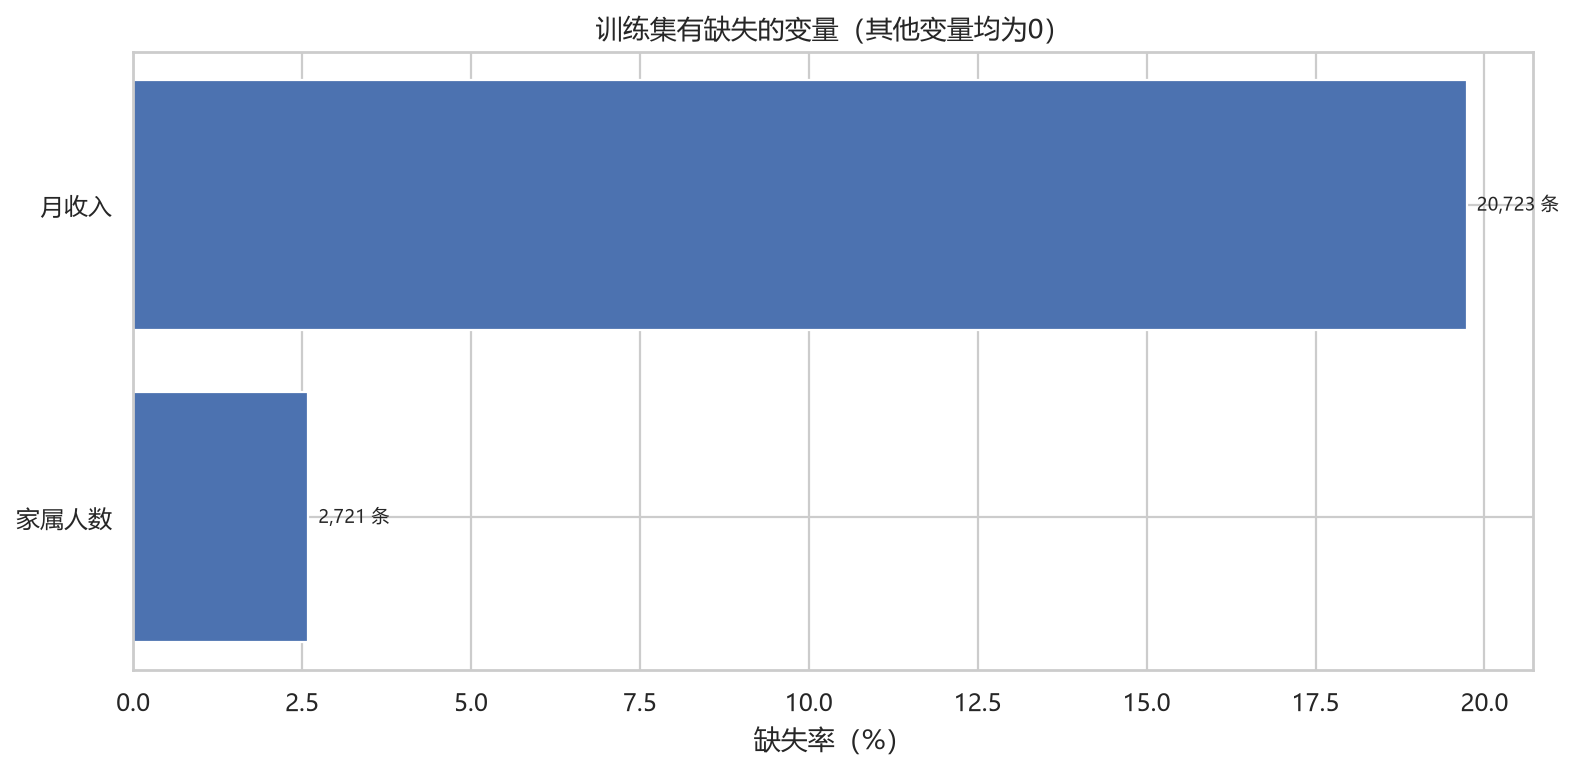

**统计结果：** 最高缺失字段为月收入：20,723条，占训练集的19.74%。

**风险含义：** 缺失可能与客户信息记录方式有关；缺失本身需要保留供后续评估。

**结论：** 填补参数只从训练集拟合，清洗前先保留缺失标记。

**局限性：** 缺失率不能说明缺失原因，也不能单凭此判断变量风险。

### missing_pattern

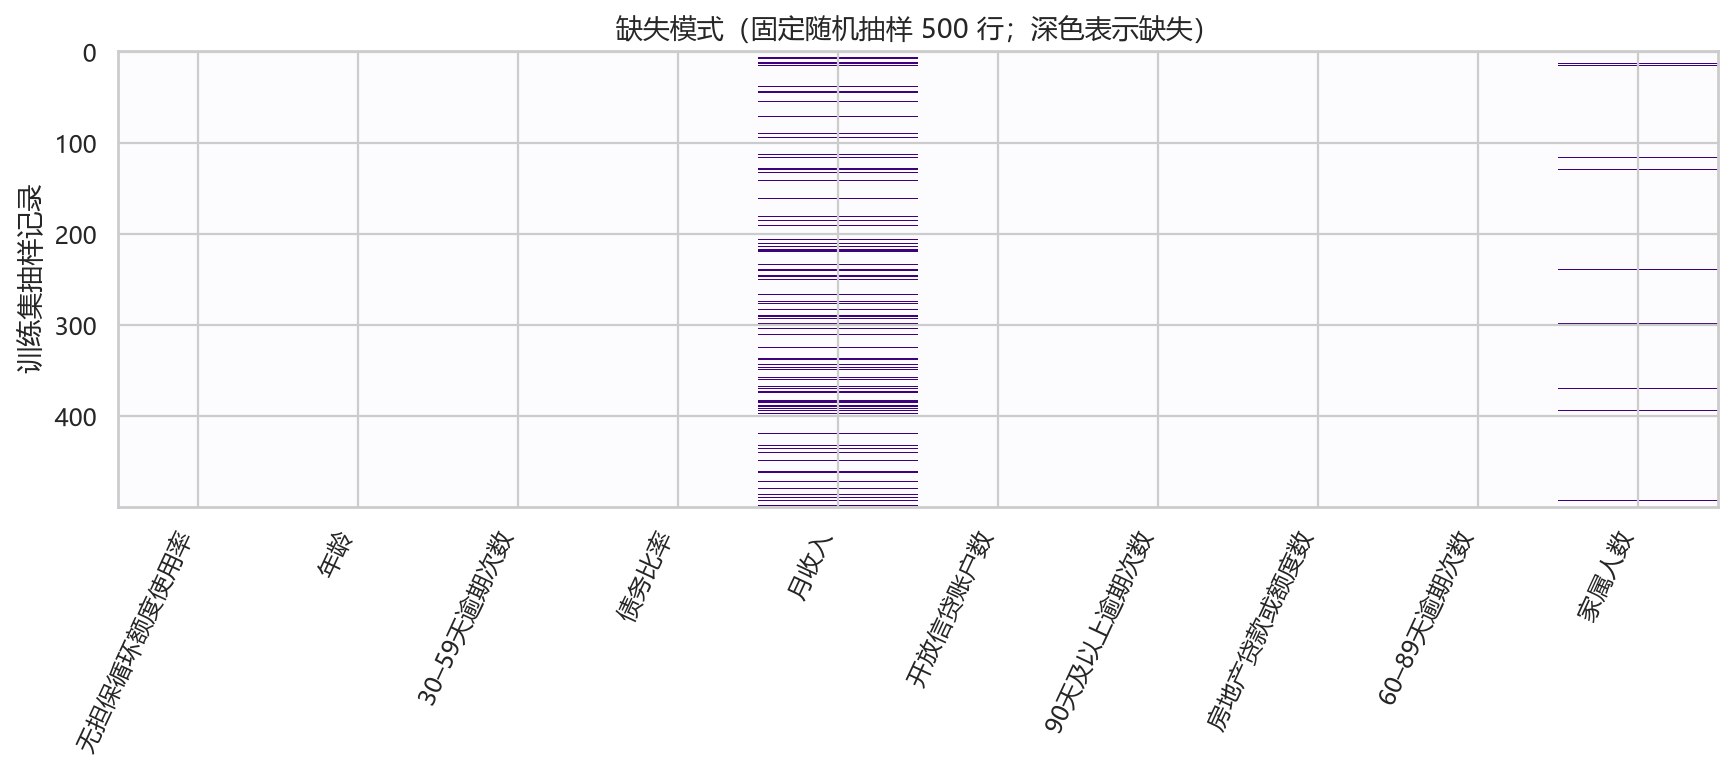

**统计结果：** 图中展示按固定随机种子抽取的500条训练记录，全量缺失数量见缺失率表。

**风险含义：** 同一行多个字段同时缺失可提示记录模式。

**结论：** 用该图辅助检查缺失是否集中出现。

**局限性：** 抽样图不代表精确缺失率；精确比例以全量训练集统计为准。

### feature_distribution

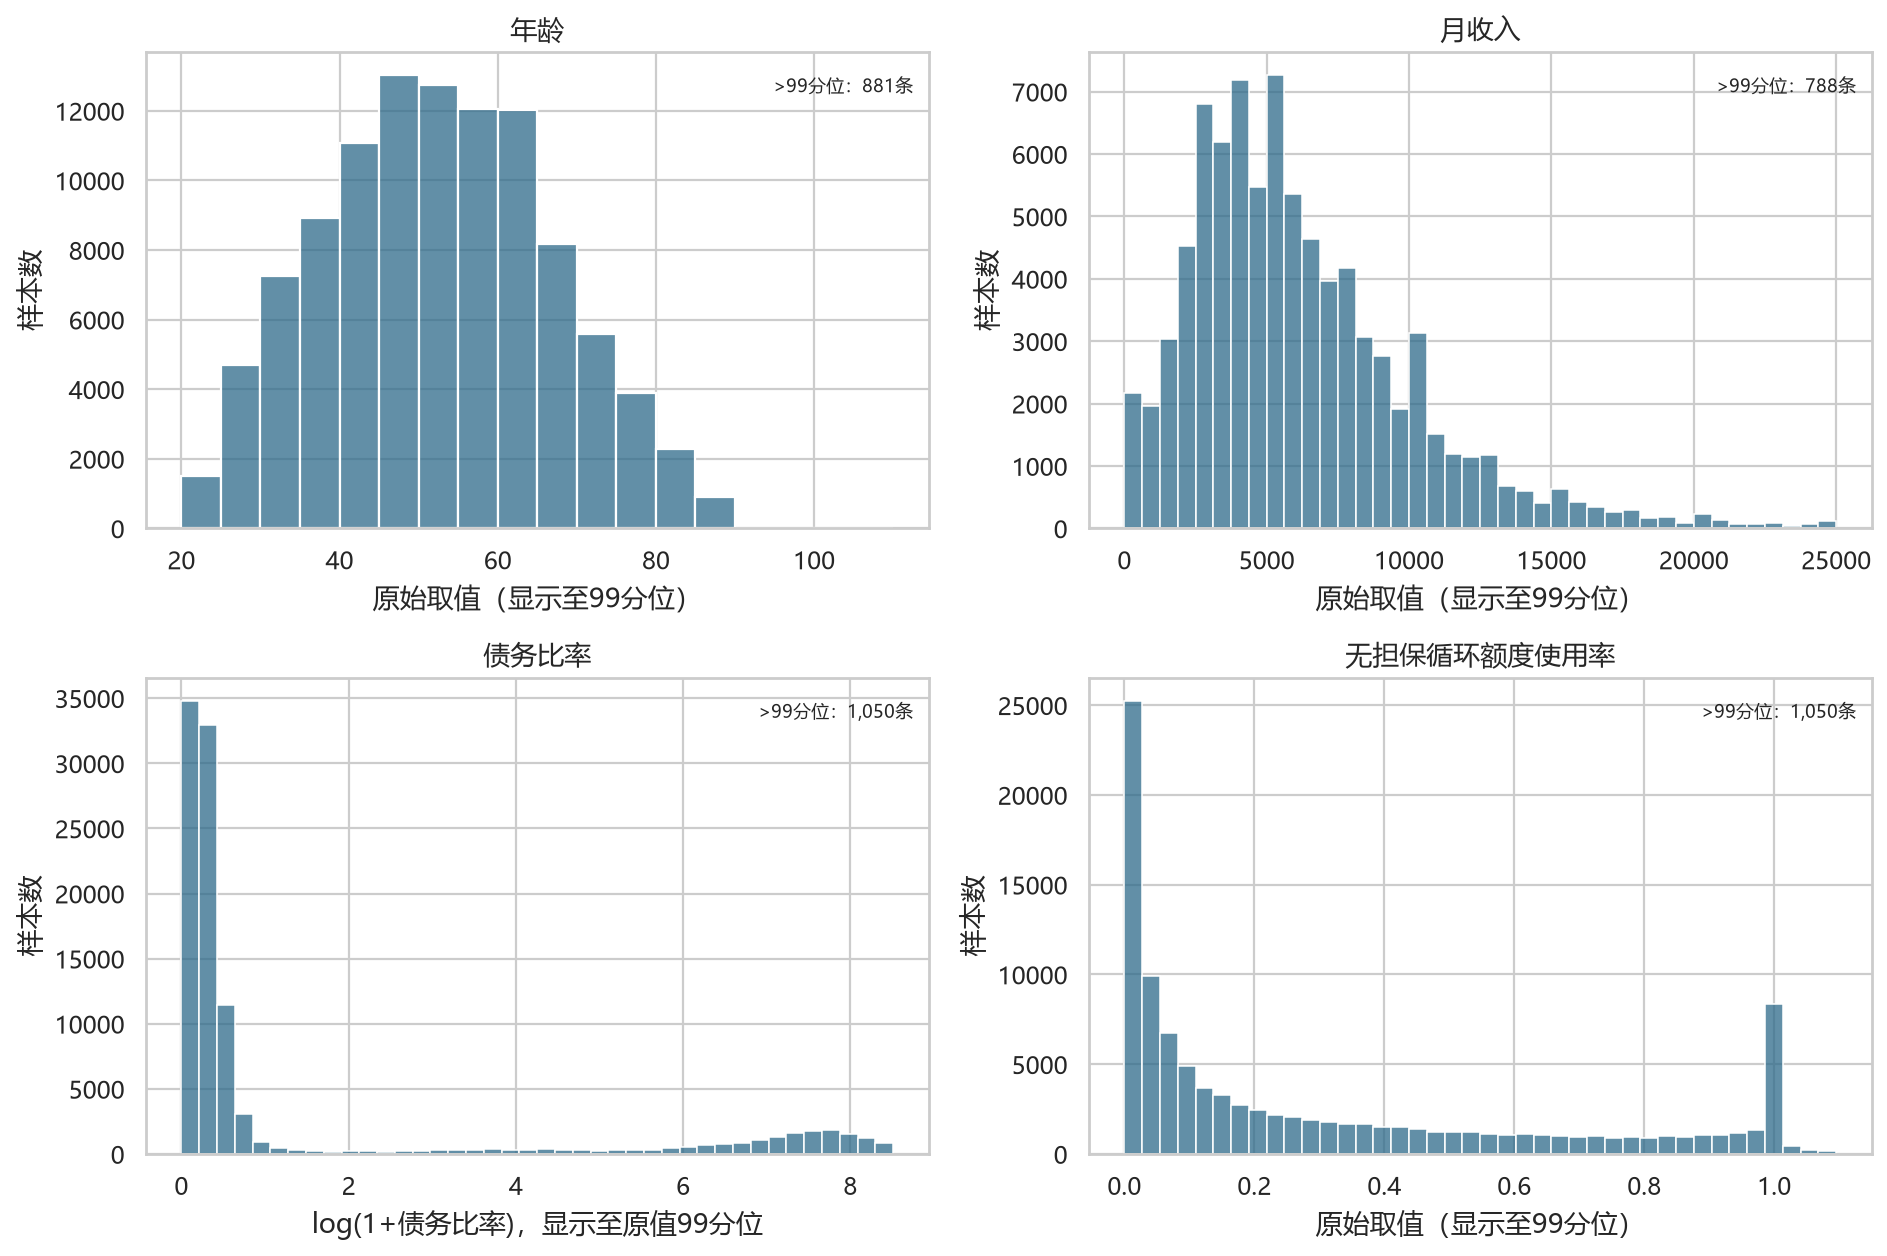

**统计结果：** 无担保循环额度使用率的99分位=1.10、最大值=50,708.00；年龄的99分位=87.00、最大值=109.00；债务比率的99分位=4,977.02、最大值=329,664.00；月收入的99分位=25,000.00、最大值=1,794,060.00。图中横轴显示至99分位；债务比率使用log(1+x)尺度，尾部数量另在图中标注。

**风险含义：** 偏态与极端尾部可能影响后续模型和分箱。

**结论：** 第二阶段保留有业务可能性的极端值，第三阶段再检验分箱稳定性。

**局限性：** 截断显示只是绘图方式，原始值及清洗数据未因此被截断。

### anomaly_counts

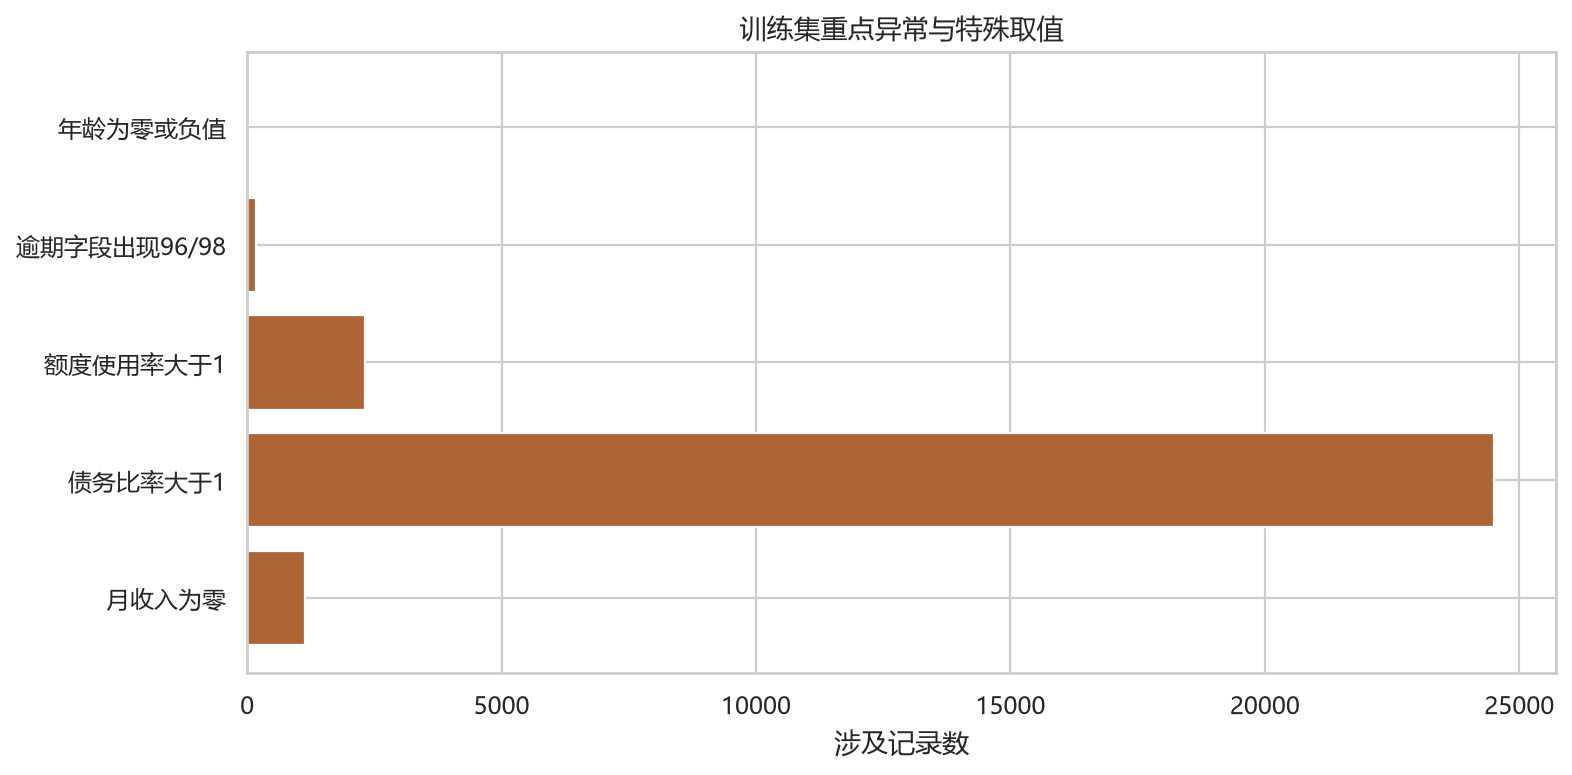

**统计结果：** 逾期字段96/98特殊值涉及182条训练记录，该组观察坏客户率为54.40%。

**风险含义：** 特殊编码可能携带风险信息，不能按普通逾期次数解释。

**结论：** 对特殊值建立标记，并使用训练集规则处理原计数字段。

**局限性：** 仅凭该数据不能确定96/98的产生原因；高坏率也不证明因果关系。

In [2]:
FIGURES = ROOT / 'reports' / 'figures' / 'eda'
def show_chart(key):
    display(Image(filename=str(FIGURES / f'{key}.png'), width=850))
    display(Markdown(narratives[key]))

for key in ['missing_rate', 'missing_pattern', 'feature_distribution', 'anomaly_counts']:
    display(Markdown(f'### {key}'))
    show_chart(key)

## 二、单变量风险分析

每组坏客户率 = 该组坏客户数 ÷ 该组样本数；风险倍数 = 该组坏率 ÷ 训练集整体坏率。星号表示样本数少于 100 或坏客户数少于 20，解释需谨慎。

### 无担保循环额度使用率

,feature,group,sample_count,bad_count,sample_share,bad_rate,risk_lift,unstable
0,RevolvingUtilizationOfUnsecuredLines,0及以下,7688,221,0.073219,0.028746,0.430086,False
1,RevolvingUtilizationOfUnsecuredLines,"(0,0.3]",57274,1201,0.545467,0.020969,0.313734,False
2,RevolvingUtilizationOfUnsecuredLines,"(0.3,0.7]",19094,1432,0.181848,0.074997,1.122075,False
3,RevolvingUtilizationOfUnsecuredLines,"(0.7,1]",18622,3303,0.177352,0.177371,2.653739,False
4,RevolvingUtilizationOfUnsecuredLines,"(1,5]",2145,843,0.020429,0.393007,5.879985,False
5,RevolvingUtilizationOfUnsecuredLines,>5,177,18,0.001686,0.101695,1.521511,True


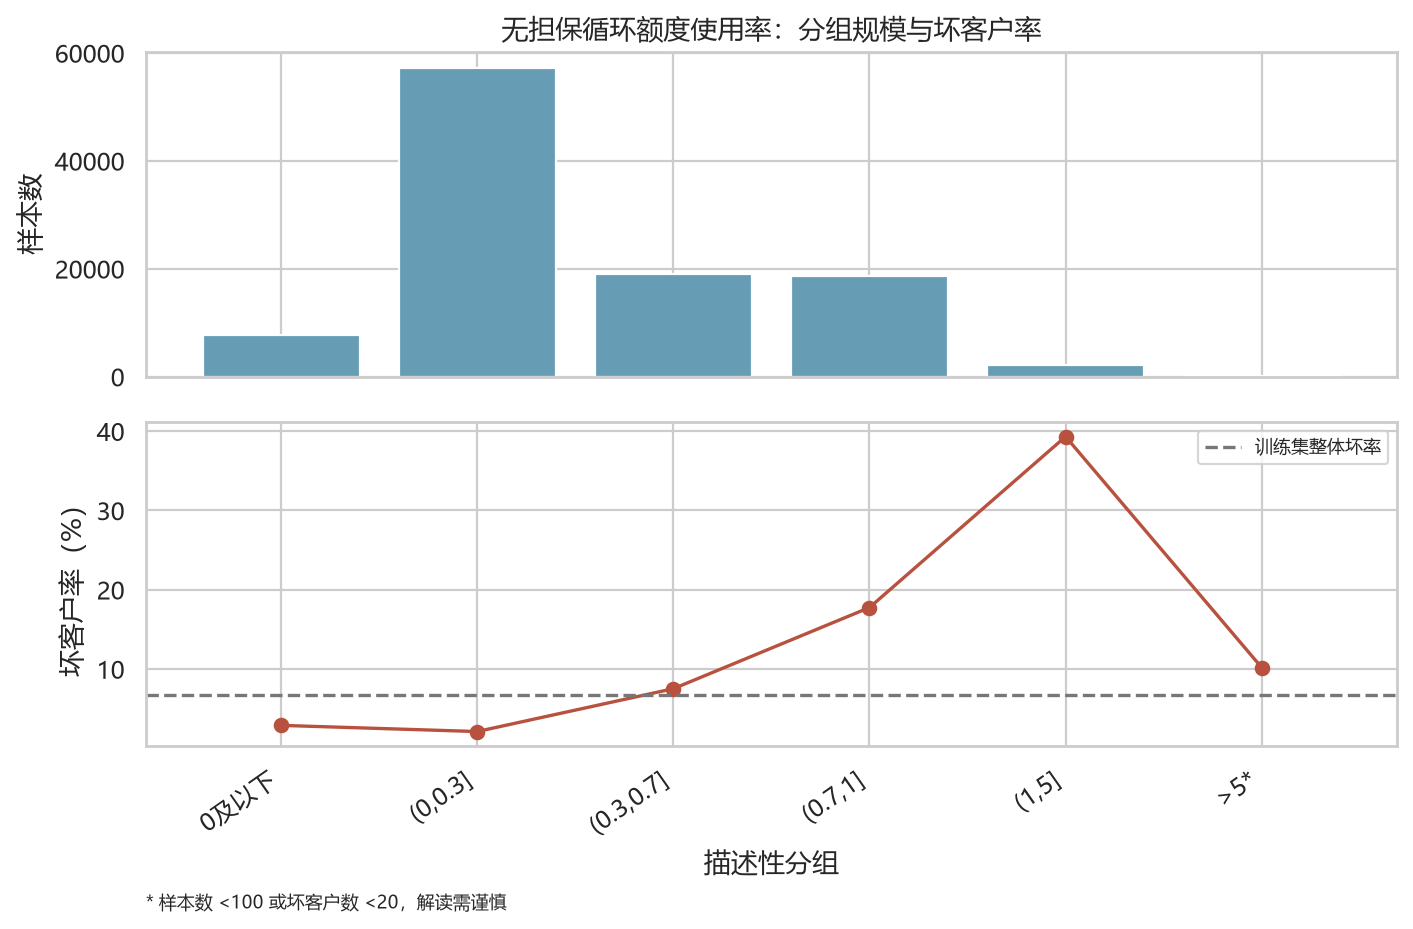

**统计结果：** 无担保循环额度使用率共6组；稳定组中，“(1,5]”坏率39.30%（n=2,145），“(0,0.3]”坏率2.10%（n=57,274）。

**风险含义：** 额度使用率反映无担保循环信用的使用程度；偏高可能提示资金周转压力。

**结论：** 这两组观察坏率相差37.20个百分点；可作为第三阶段分箱与稳定性检查的线索。

**局限性：** 这是训练集描述性分组；小样本或坏客户少于20人的组已标记，组间差异不代表因果关系，也不等同于正式WOE分箱。

### 年龄

,feature,group,sample_count,bad_count,sample_share,bad_rate,risk_lift,unstable
0,age,≤25岁,2169,234,0.020657,0.107884,1.614107,False
1,age,26–35岁,12821,1398,0.122105,0.109040,1.631403,False
2,age,36–45岁,20947,1845,0.199495,0.088079,1.317803,False
3,age,46–55岁,25658,1934,0.244362,0.075376,1.127742,False
4,age,56–65岁,23513,1114,0.223933,0.047378,0.708848,False
5,age,>65岁,19892,493,0.189448,0.024784,0.370804,False


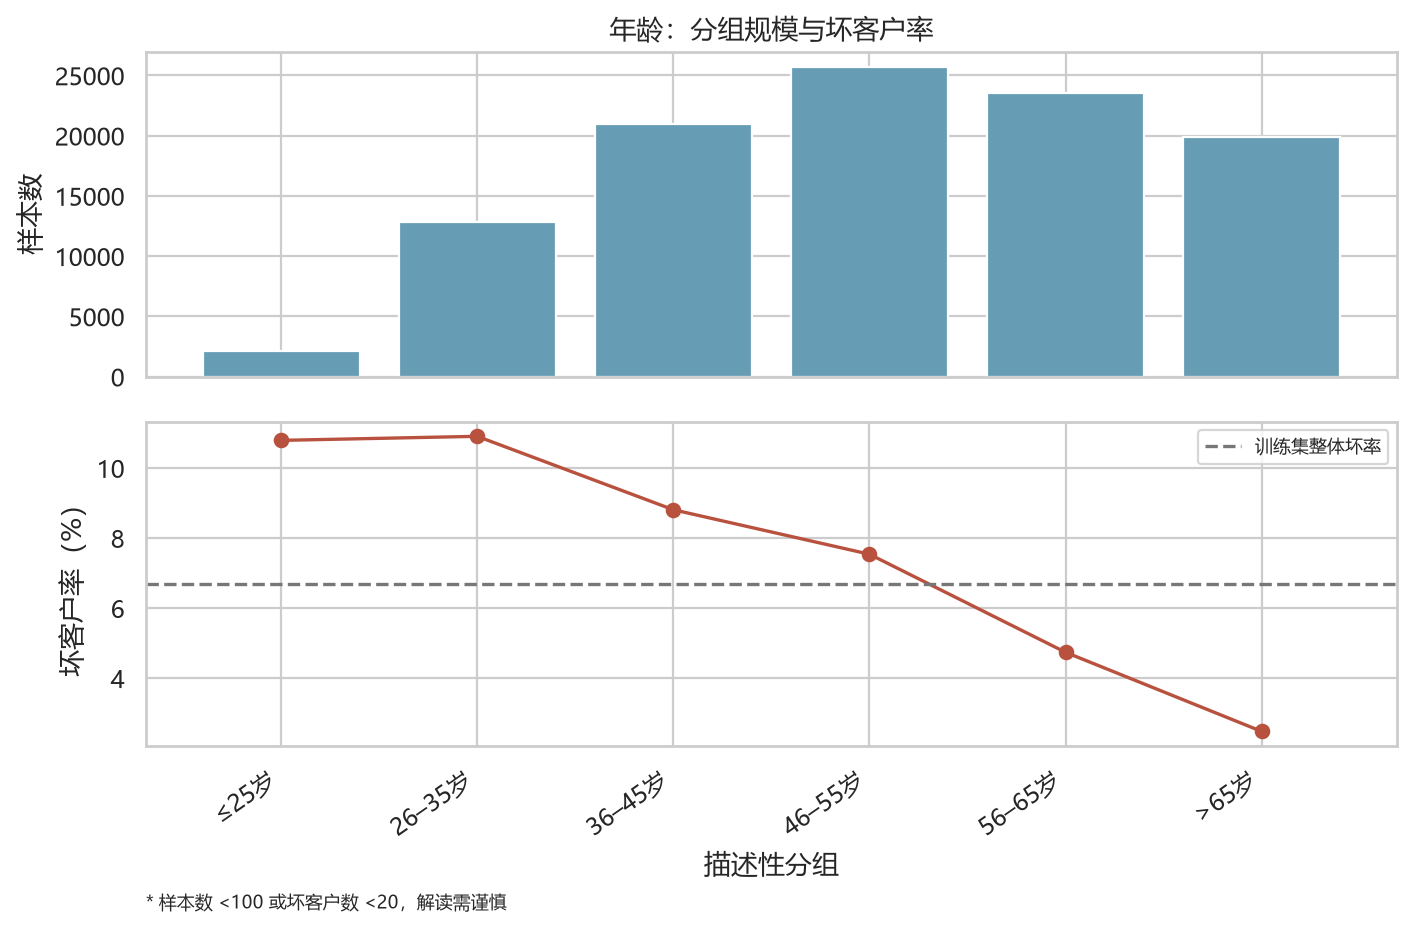

**统计结果：** 年龄共6组；稳定组中，“26–35岁”坏率10.90%（n=12,821），“>65岁”坏率2.48%（n=19,892）。

**风险含义：** 年龄反映客户所处人生阶段，不能据此直接判断单个客户的信用状况。

**结论：** 这两组观察坏率相差8.43个百分点；可作为第三阶段分箱与稳定性检查的线索。

**局限性：** 这是训练集描述性分组；小样本或坏客户少于20人的组已标记，组间差异不代表因果关系，也不等同于正式WOE分箱。

### 30–59天逾期次数

,feature,group,sample_count,bad_count,sample_share,bad_rate,risk_lift,unstable
0,NumberOfTime30-59DaysPastDueNotWorse,0次,88178,3560,0.839790,0.040373,0.604040,False
1,NumberOfTime30-59DaysPastDueNotWorse,1次,11252,1660,0.107162,0.147529,2.207264,False
2,NumberOfTime30-59DaysPastDueNotWorse,2次,3225,866,0.030714,0.268527,4.017576,False
3,NumberOfTime30-59DaysPastDueNotWorse,≥3次,2163,833,0.020600,0.385113,5.761883,False
4,NumberOfTime30-59DaysPastDueNotWorse,96/98特殊值,182,99,0.001733,0.543956,8.138413,False


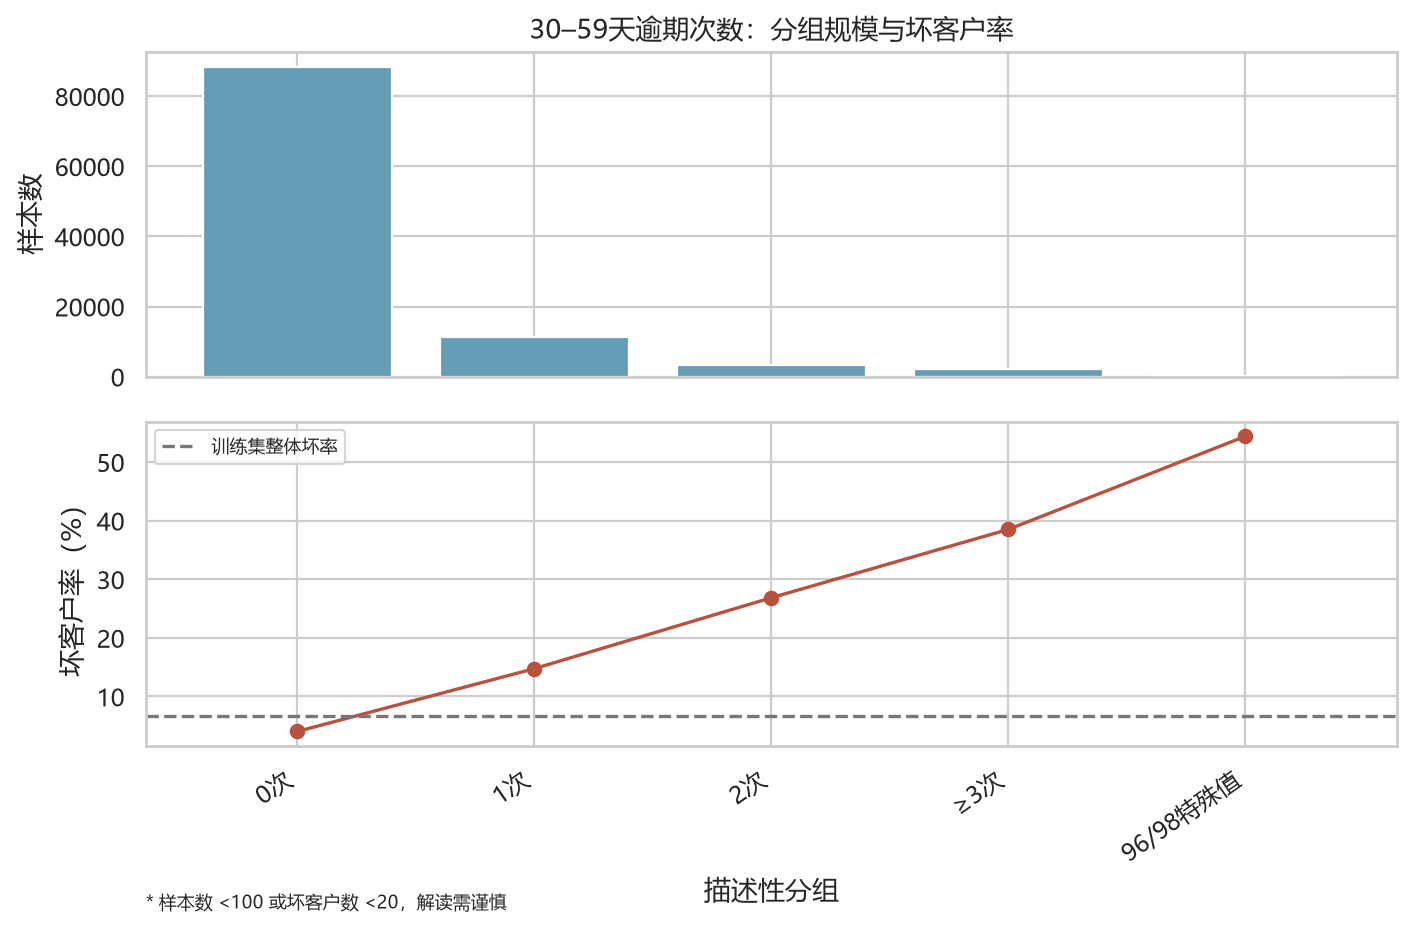

**统计结果：** 30–59天逾期次数共5组；稳定组中，“96/98特殊值”坏率54.40%（n=182），“0次”坏率4.04%（n=88,178）。

**风险含义：** 30–59天逾期记录反映较早期的还款延迟。

**结论：** 这两组观察坏率相差50.36个百分点；可作为第三阶段分箱与稳定性检查的线索。

**局限性：** 这是训练集描述性分组；小样本或坏客户少于20人的组已标记，组间差异不代表因果关系，也不等同于正式WOE分箱。

### 债务比率

,feature,group,sample_count,bad_count,sample_share,bad_rate,risk_lift,unstable
0,DebtRatio,0及以下,2908,241,0.027695,0.082875,1.239934,False
1,DebtRatio,"(0,0.25]",33700,1943,0.320952,0.057656,0.862619,False
2,DebtRatio,"(0.25,0.5]",29013,1780,0.276314,0.061352,0.917917,False
3,DebtRatio,"(0.5,1]",14880,1487,0.141714,0.099933,1.495147,False
4,DebtRatio,"(1,5]",3825,451,0.036429,0.117908,1.764091,False
5,DebtRatio,>5,20674,1116,0.196895,0.053981,0.807636,False


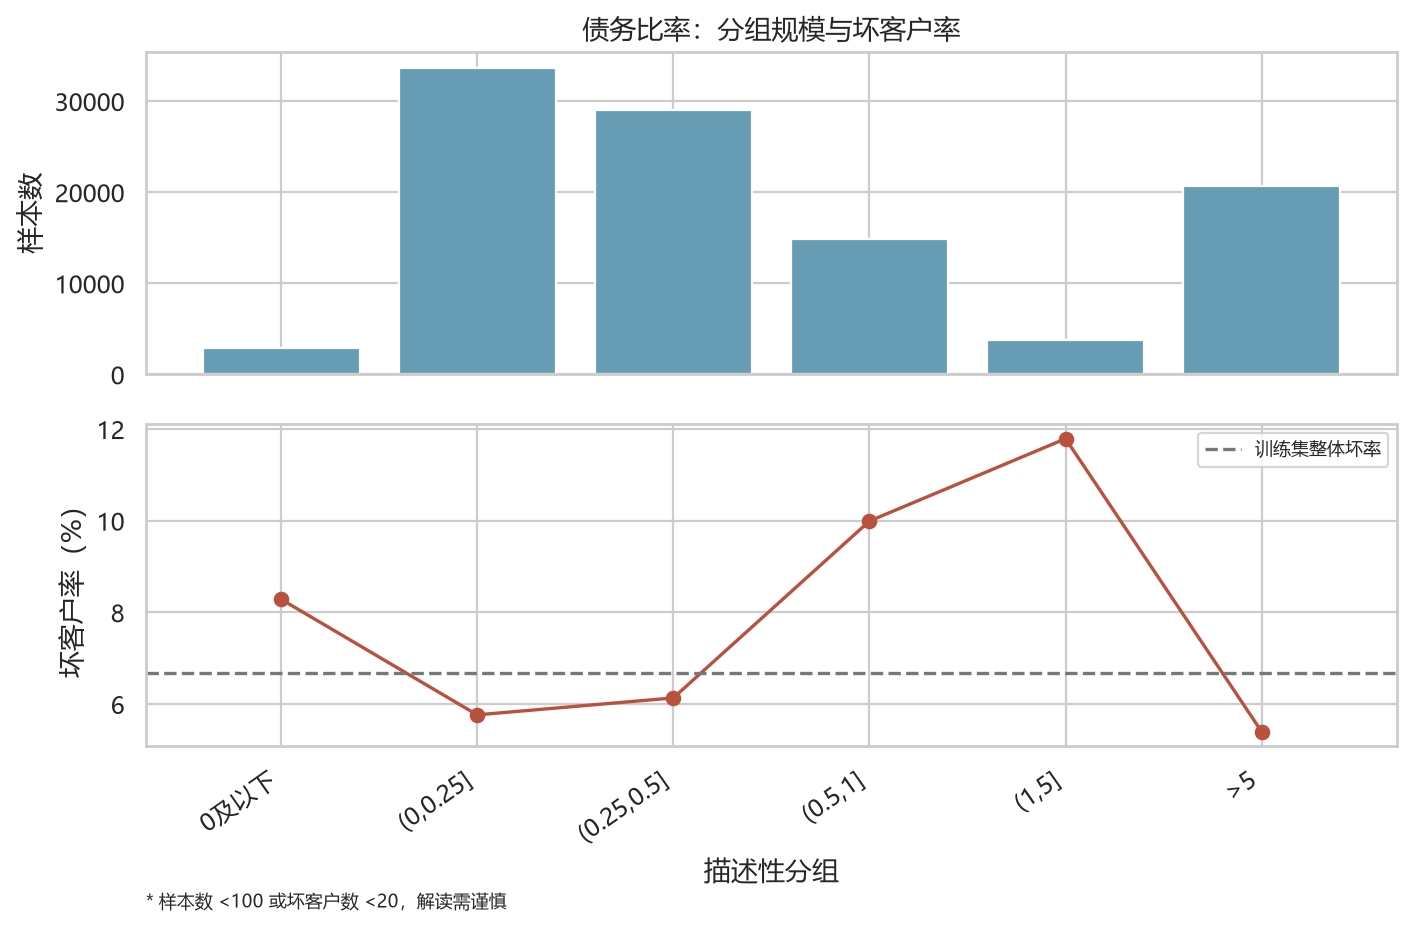

**统计结果：** 债务比率共6组；稳定组中，“(1,5]”坏率11.79%（n=3,825），“>5”坏率5.40%（n=20,674）。

**风险含义：** 债务比率可能反映偿债压力，但其极端值需结合月收入和字段定义解读。

**结论：** 这两组观察坏率相差6.39个百分点；可作为第三阶段分箱与稳定性检查的线索。

**局限性：** 这是训练集描述性分组；小样本或坏客户少于20人的组已标记，组间差异不代表因果关系，也不等同于正式WOE分箱。

### 月收入

,feature,group,sample_count,bad_count,sample_share,bad_rate,risk_lift,unstable
0,MonthlyIncome,"(-0.001, 3000.0]",17632,1604,0.167924,0.090971,1.361065,False
1,MonthlyIncome,"(3000.0, 4516.4]",16079,1382,0.153133,0.085951,1.285953,False
2,MonthlyIncome,"(4516.4, 6300.0]",16985,1207,0.161762,0.071063,1.063207,False
3,MonthlyIncome,"(6300.0, 9061.0]",16727,921,0.159305,0.055061,0.823792,False
4,MonthlyIncome,"(9061.0, 1794060.0]",16854,768,0.160514,0.045568,0.681764,False
5,MonthlyIncome,缺失,20723,1136,0.197362,0.054818,0.820166,False


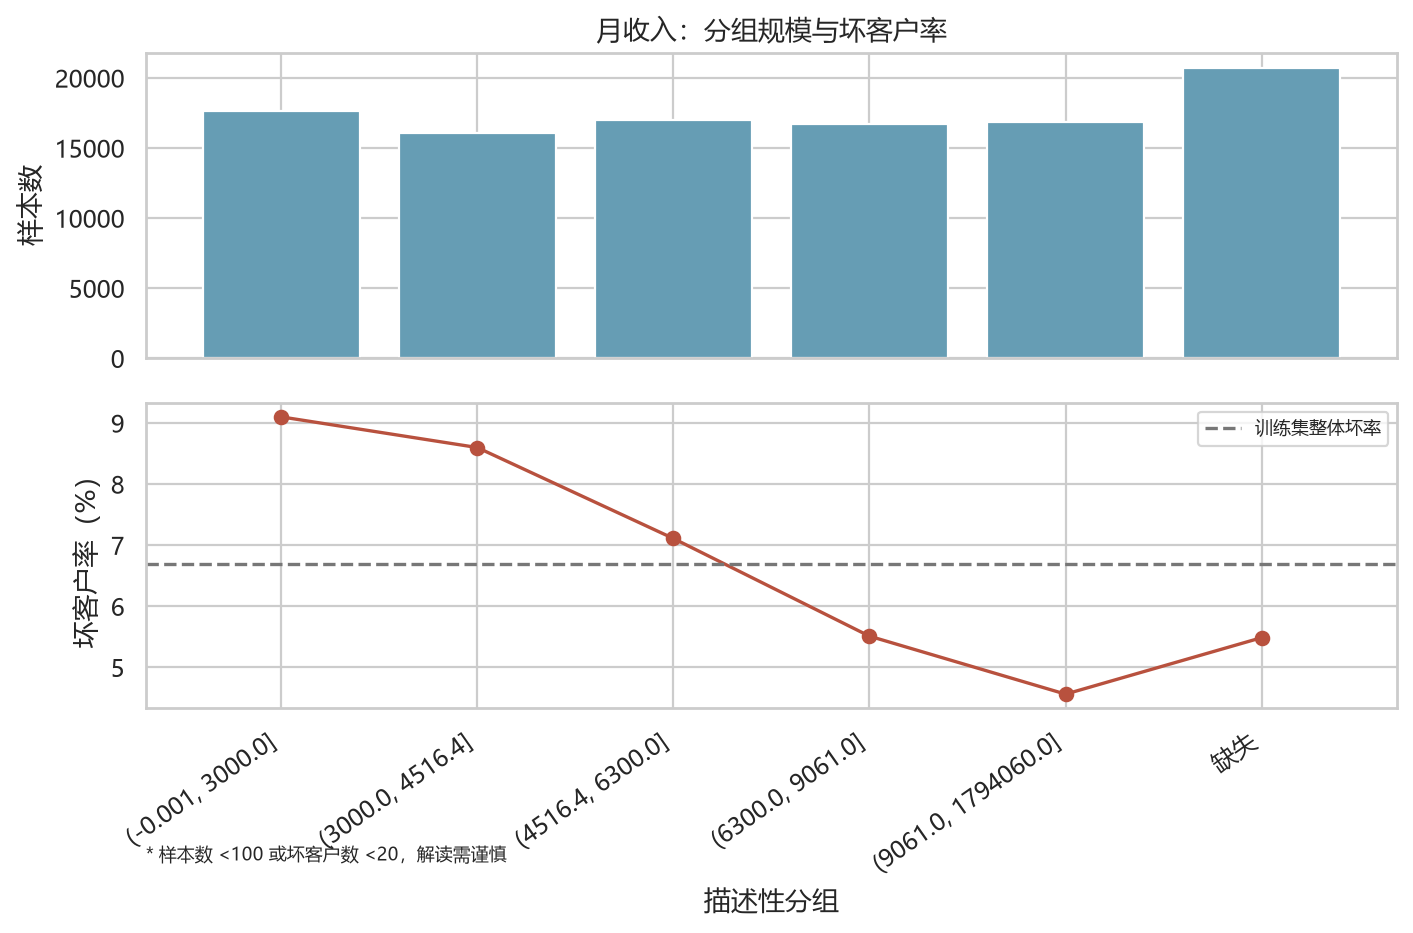

**统计结果：** 月收入共6组；稳定组中，“(-0.001, 3000.0]”坏率9.10%（n=17,632），“(9061.0, 1794060.0]”坏率4.56%（n=16,854）。

**风险含义：** 月收入可提示偿债资源；缺失收入是单独展示的群体。

**结论：** 这两组观察坏率相差4.54个百分点；可作为第三阶段分箱与稳定性检查的线索。

**局限性：** 这是训练集描述性分组；小样本或坏客户少于20人的组已标记，组间差异不代表因果关系，也不等同于正式WOE分箱。

### 开放信贷账户数

,feature,group,sample_count,bad_count,sample_share,bad_rate,risk_lift,unstable
0,NumberOfOpenCreditLinesAndLoans,0条,1321,345,0.012581,0.261166,3.907439,False
1,NumberOfOpenCreditLinesAndLoans,1–3条,14039,1309,0.133705,0.093240,1.395017,False
2,NumberOfOpenCreditLinesAndLoans,4–7条,35928,2157,0.342171,0.060037,0.898241,False
3,NumberOfOpenCreditLinesAndLoans,8–15条,43986,2540,0.418914,0.057746,0.863963,False
4,NumberOfOpenCreditLinesAndLoans,>15条,9726,667,0.092629,0.068579,1.026048,False


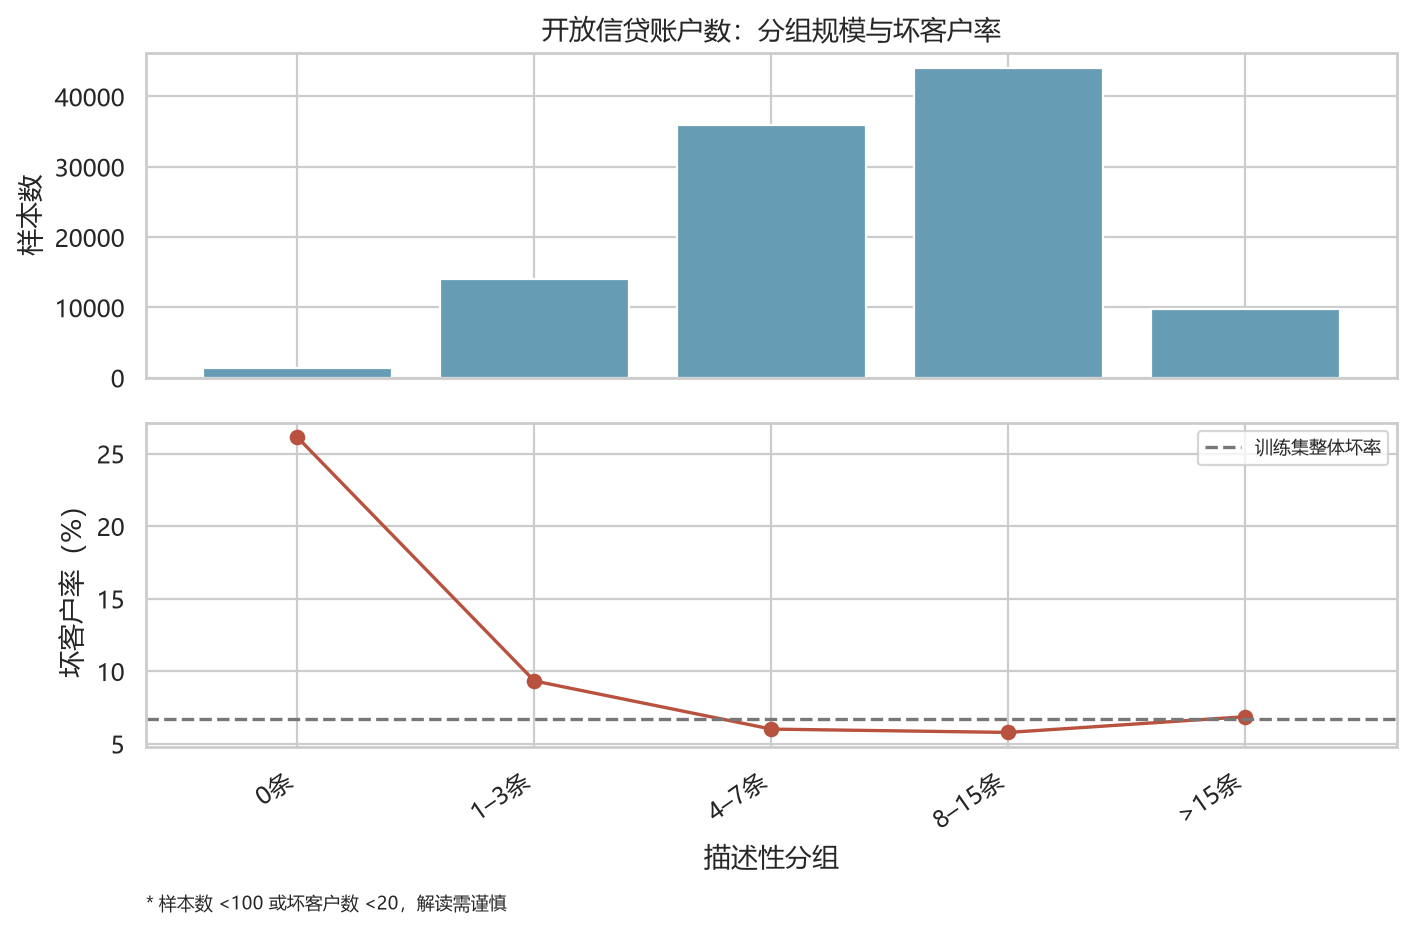

**统计结果：** 开放信贷账户数共5组；稳定组中，“0条”坏率26.12%（n=1,321），“8–15条”坏率5.77%（n=43,986）。

**风险含义：** 开放账户数反映信贷使用广度，其风险方向未必单调。

**结论：** 这两组观察坏率相差20.34个百分点；可作为第三阶段分箱与稳定性检查的线索。

**局限性：** 这是训练集描述性分组；小样本或坏客户少于20人的组已标记，组间差异不代表因果关系，也不等同于正式WOE分箱。

### 90天及以上逾期次数

,feature,group,sample_count,bad_count,sample_share,bad_rate,risk_lift,unstable
0,NumberOfTimes90DaysLate,0次,99103,4558,0.943838,0.045993,0.688119,False
1,NumberOfTimes90DaysLate,1次,3723,1261,0.035457,0.338705,5.067549,False
2,NumberOfTimes90DaysLate,2次,1094,535,0.010419,0.489031,7.316652,False
3,NumberOfTimes90DaysLate,≥3次,898,565,0.008552,0.629176,9.413433,False
4,NumberOfTimes90DaysLate,96/98特殊值,182,99,0.001733,0.543956,8.138413,False


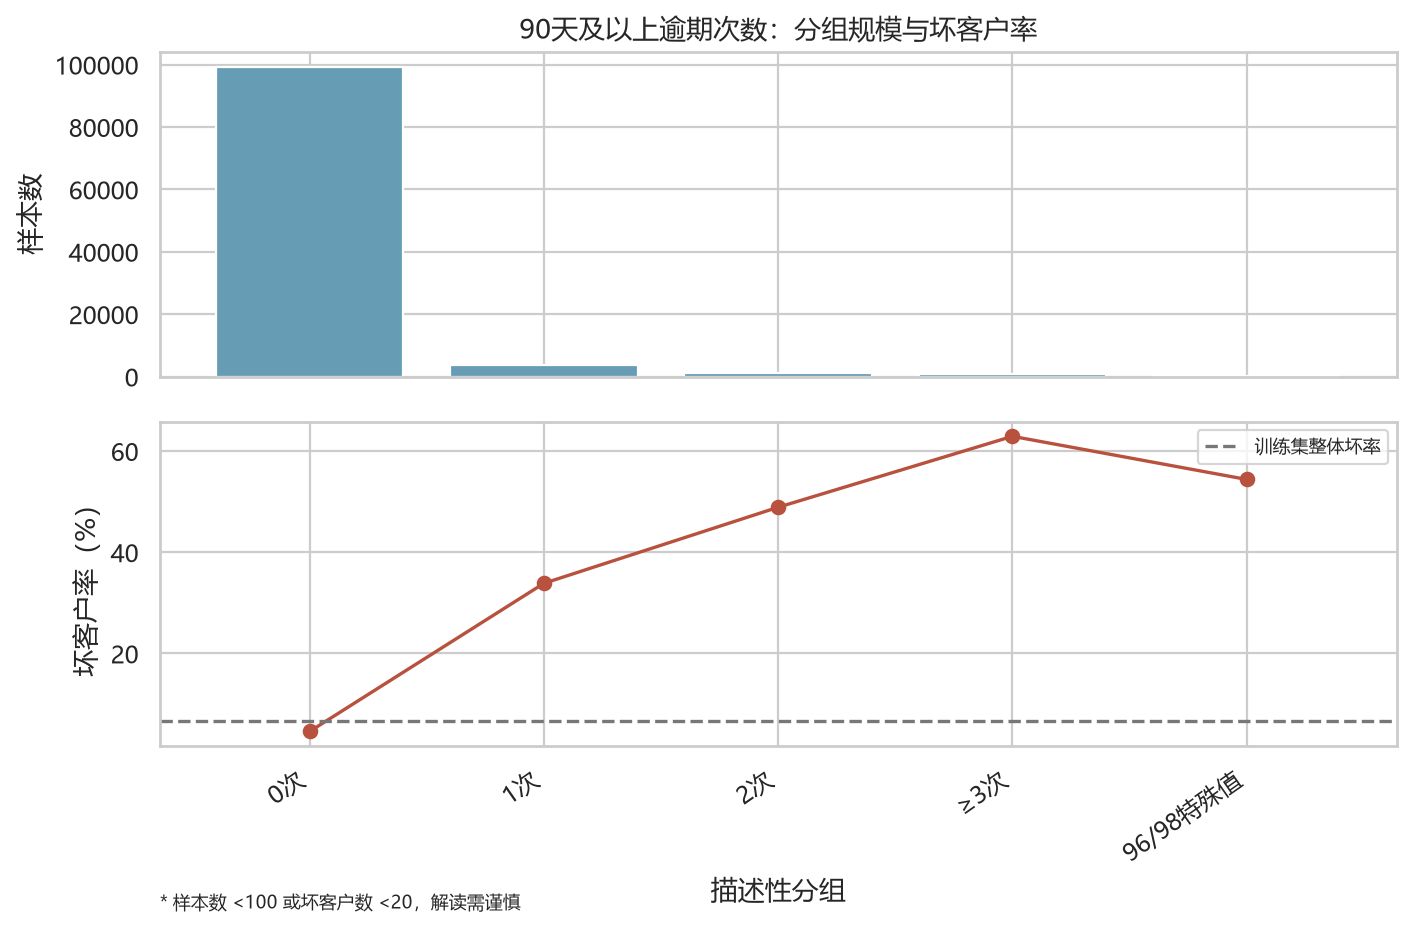

**统计结果：** 90天及以上逾期次数共5组；稳定组中，“≥3次”坏率62.92%（n=898），“0次”坏率4.60%（n=99,103）。

**风险含义：** 90天及以上逾期记录反映严重的既往还款问题。

**结论：** 这两组观察坏率相差58.32个百分点；可作为第三阶段分箱与稳定性检查的线索。

**局限性：** 这是训练集描述性分组；小样本或坏客户少于20人的组已标记，组间差异不代表因果关系，也不等同于正式WOE分箱。

### 房地产贷款或额度数

,feature,group,sample_count,bad_count,sample_share,bad_rate,risk_lift,unstable
0,NumberRealEstateLoansOrLines,0条,39193,3255,0.373267,0.083051,1.242563,False
1,NumberRealEstateLoansOrLines,1条,36731,1919,0.349819,0.052245,0.781660,False
2,NumberRealEstateLoansOrLines,2条,22106,1240,0.210533,0.056093,0.839242,False
3,NumberRealEstateLoansOrLines,≥3条,6970,604,0.066381,0.086657,1.296523,False


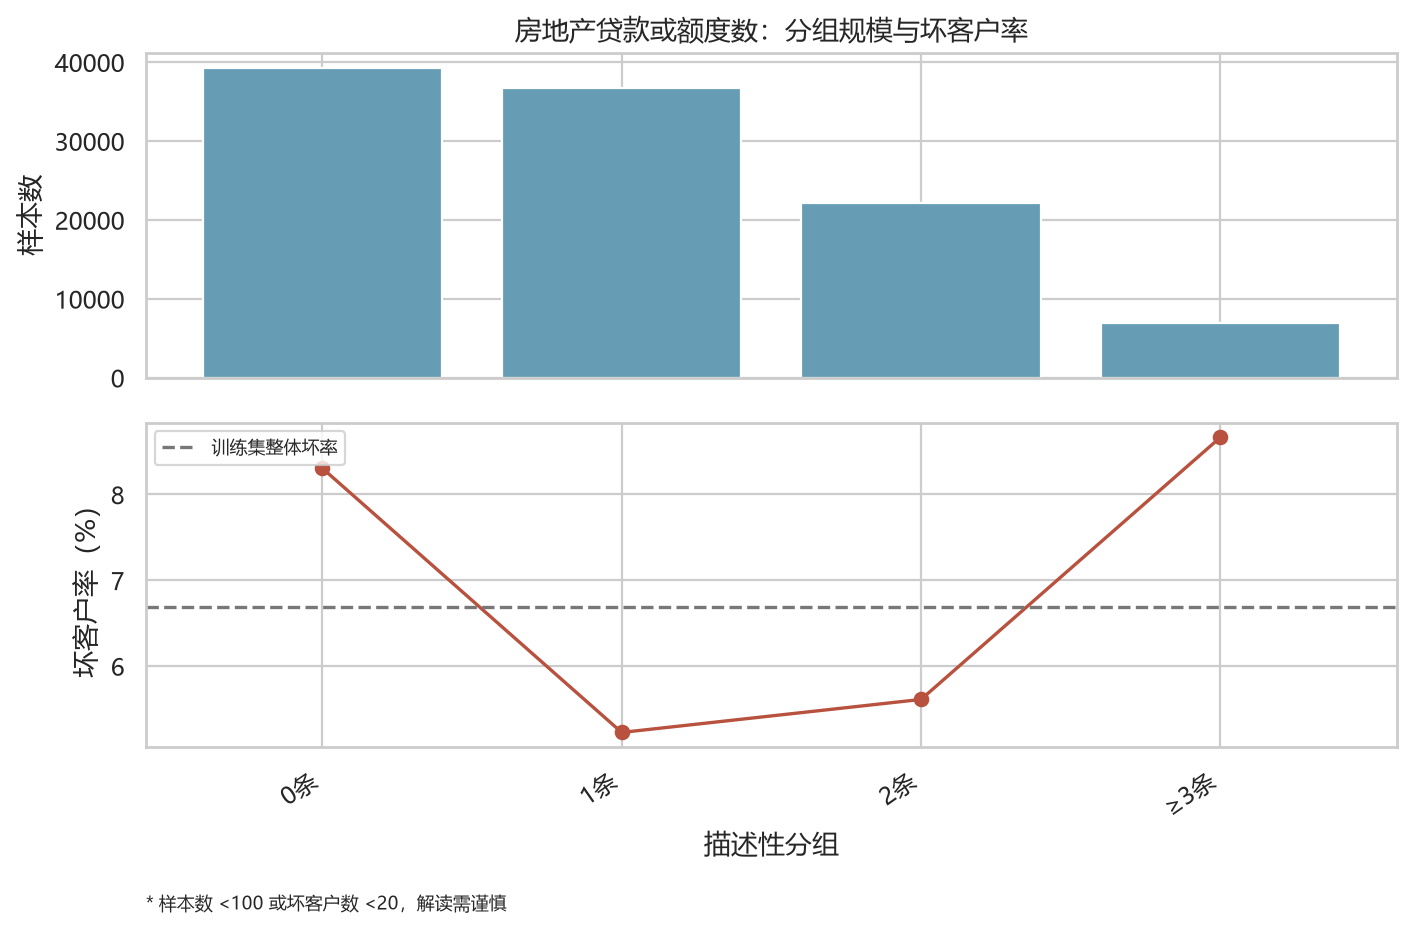

**统计结果：** 房地产贷款或额度数共4组；稳定组中，“≥3条”坏率8.67%（n=6,970），“1条”坏率5.22%（n=36,731）。

**风险含义：** 房地产贷款或额度数反映信贷结构，不能单独理解为资产或负债水平。

**结论：** 这两组观察坏率相差3.44个百分点；可作为第三阶段分箱与稳定性检查的线索。

**局限性：** 这是训练集描述性分组；小样本或坏客户少于20人的组已标记，组间差异不代表因果关系，也不等同于正式WOE分箱。

### 60–89天逾期次数

,feature,group,sample_count,bad_count,sample_share,bad_rate,risk_lift,unstable
0,NumberOfTime60-89DaysPastDueNotWorse,0次,99662,5072,0.949162,0.050892,0.761422,False
1,NumberOfTime60-89DaysPastDueNotWorse,1次,4049,1262,0.038562,0.311682,4.663237,False
2,NumberOfTime60-89DaysPastDueNotWorse,2次,767,383,0.007305,0.499348,7.471010,False
3,NumberOfTime60-89DaysPastDueNotWorse,≥3次,340,202,0.003238,0.594118,8.888908,False
4,NumberOfTime60-89DaysPastDueNotWorse,96/98特殊值,182,99,0.001733,0.543956,8.138413,False


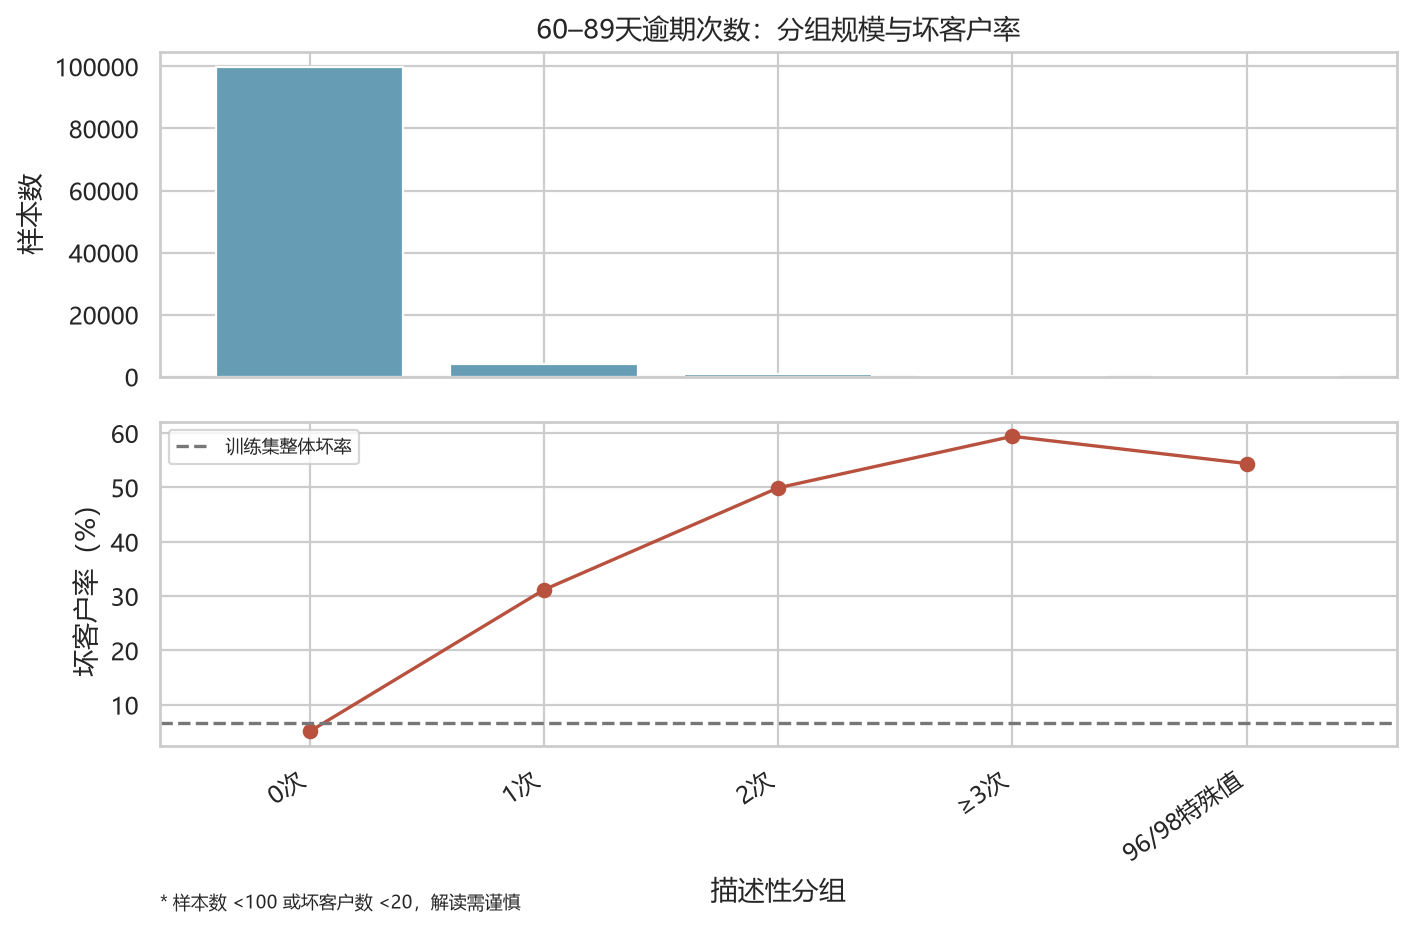

**统计结果：** 60–89天逾期次数共5组；稳定组中，“≥3次”坏率59.41%（n=340），“0次”坏率5.09%（n=99,662）。

**风险含义：** 60–89天逾期记录反映较重的既往还款延迟。

**结论：** 这两组观察坏率相差54.32个百分点；可作为第三阶段分箱与稳定性检查的线索。

**局限性：** 这是训练集描述性分组；小样本或坏客户少于20人的组已标记，组间差异不代表因果关系，也不等同于正式WOE分箱。

### 家属人数

,feature,group,sample_count,bad_count,sample_share,bad_rate,risk_lift,unstable
0,NumberOfDependents,0人,60782,3580,0.578876,0.058899,0.881219,False
1,NumberOfDependents,1人,18498,1366,0.176171,0.073846,1.104846,False
2,NumberOfDependents,2人,13644,1102,0.129943,0.080768,1.208414,False
3,NumberOfDependents,≥3人,9355,857,0.089095,0.091609,1.370607,False
4,NumberOfDependents,缺失,2721,113,0.025914,0.041529,0.621335,False


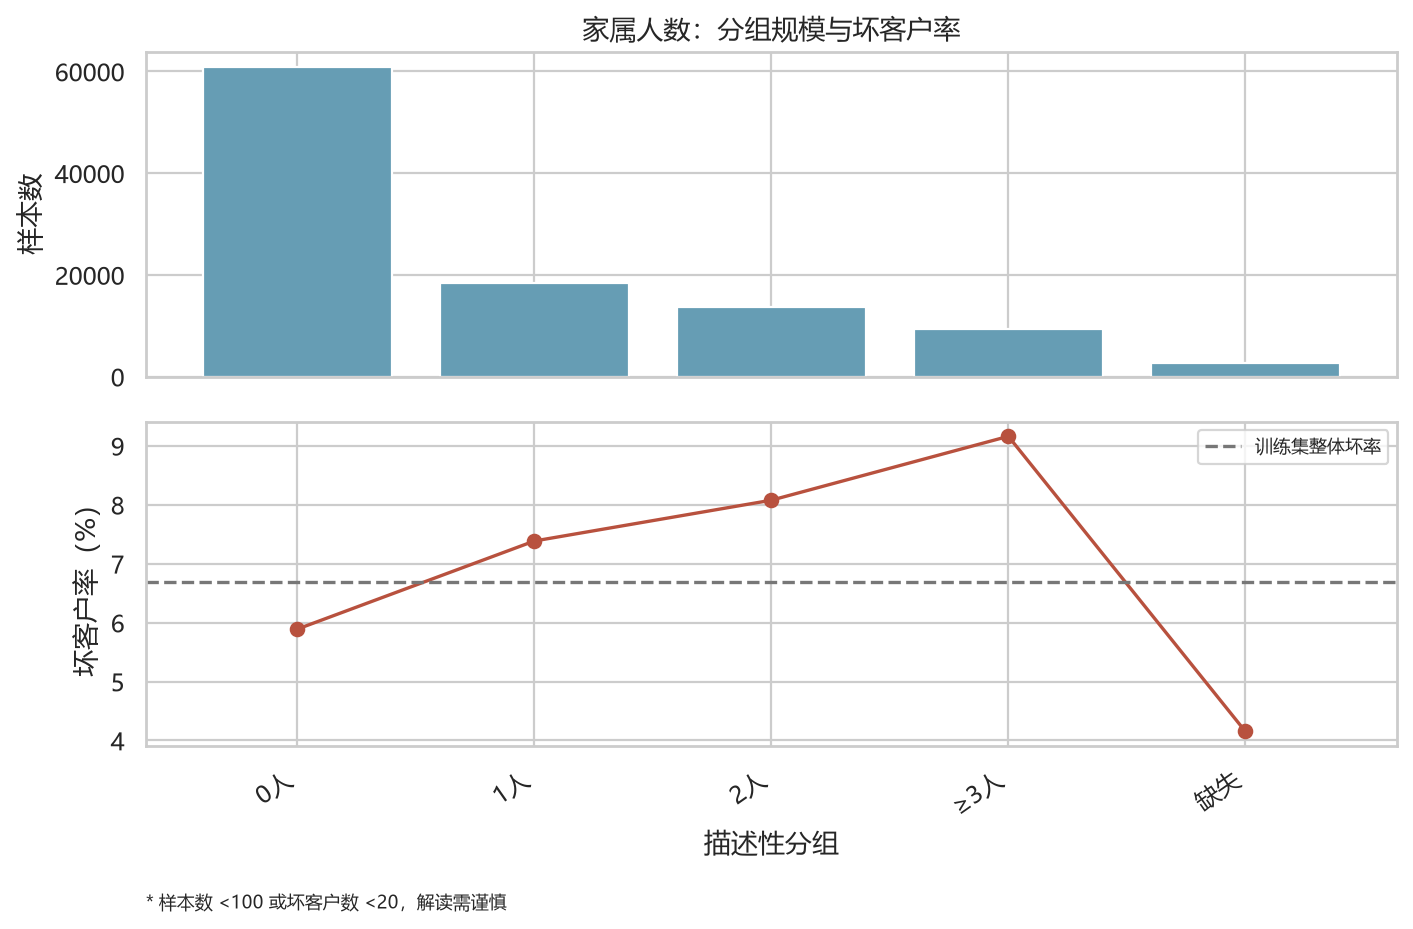

**统计结果：** 家属人数共5组；稳定组中，“≥3人”坏率9.16%（n=9,355），“缺失”坏率4.15%（n=2,721）。

**风险含义：** 家属人数可能与家庭支出相关，但不等同于真实支出或偿债能力。

**结论：** 这两组观察坏率相差5.01个百分点；可作为第三阶段分箱与稳定性检查的线索。

**局限性：** 这是训练集描述性分组；小样本或坏客户少于20人的组已标记，组间差异不代表因果关系，也不等同于正式WOE分箱。

In [3]:
from src.data_processing.schema import FEATURES
from src.data_processing.narratives import FEATURE_NAMES
for feature in FEATURES:
    display(Markdown(f'### {FEATURE_NAMES[feature]}'))
    display(eda.group_risks[feature])
    show_chart(f'risk_{feature}')

## 三、相关性、变量交互与客户群体

Spearman 相关系数描述单调关系。二维坏率图只展示达到样本与坏客户数稳定性提示阈值的单元格，空白不等于零风险。

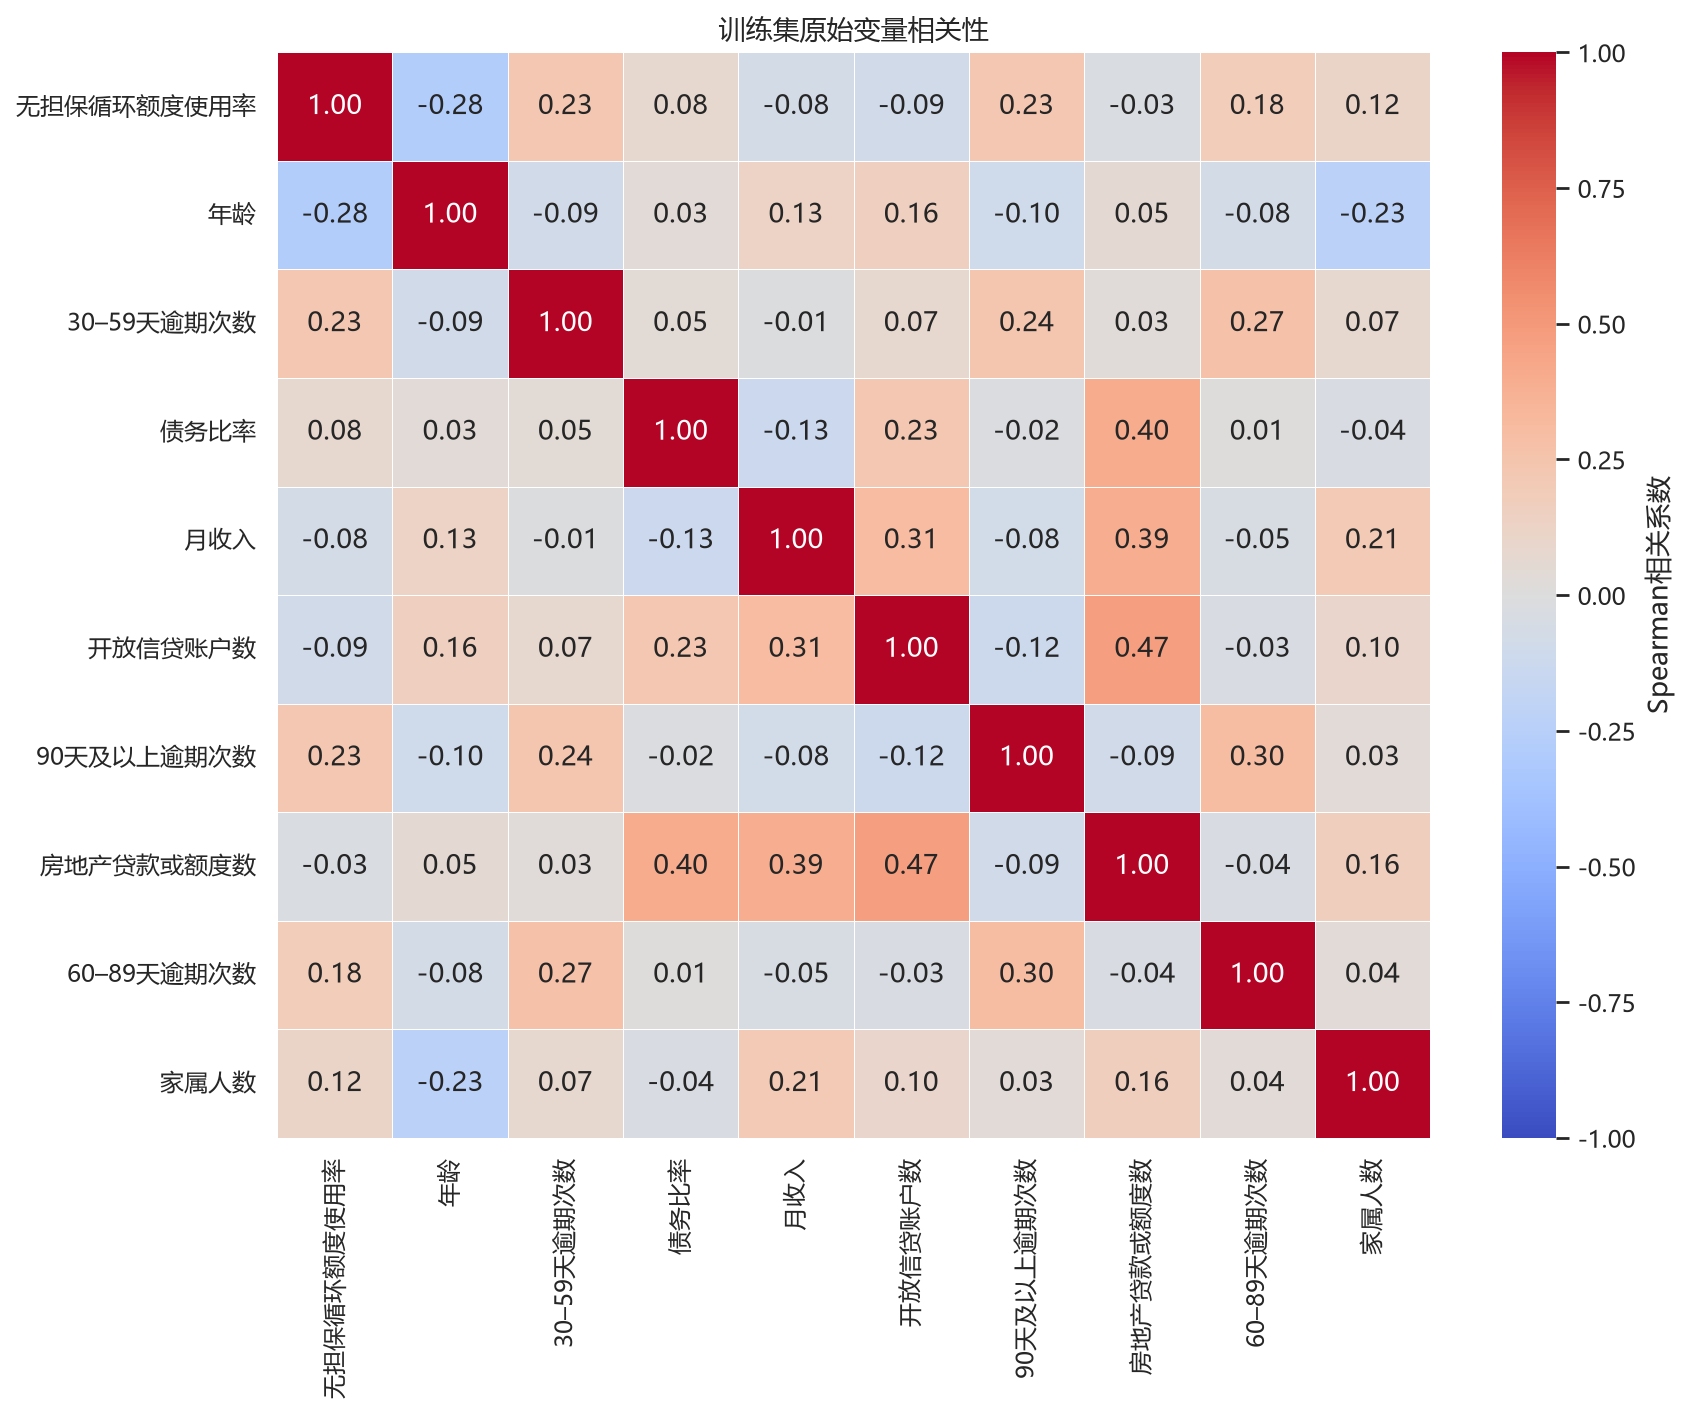

**统计结果：** 训练集绝对相关性最高的一对原始变量为开放信贷账户数与房地产贷款或额度数，Spearman系数0.471。

**风险含义：** 相关变量可能表达相近信息，后续建模需检查冗余。

**结论：** 第三阶段再结合业务意义、IV和共线性证据决定是否保留。

**局限性：** Spearman只反映单调关系；缺失和特殊逾期值已从相关计算中排除，相关不代表因果。

### 年龄×90天逾期

,group_a,group_b,sample_count,bad_count,bad_rate,unstable
0,≤25岁,0次,1942,145,0.074665,False
1,≤25岁,1次,110,39,0.354545,False
2,≤25岁,2次,35,18,0.514286,True
3,≤25岁,≥3次,18,10,0.555556,True
4,≤25岁,96/98特殊值,64,22,0.343750,True
5,26–35岁,0次,11602,863,0.074384,False
6,26–35岁,1次,719,260,0.361613,False
7,26–35岁,2次,235,115,0.489362,False
8,26–35岁,≥3次,211,129,0.611374,False
9,26–35岁,96/98特殊值,54,31,0.574074,True


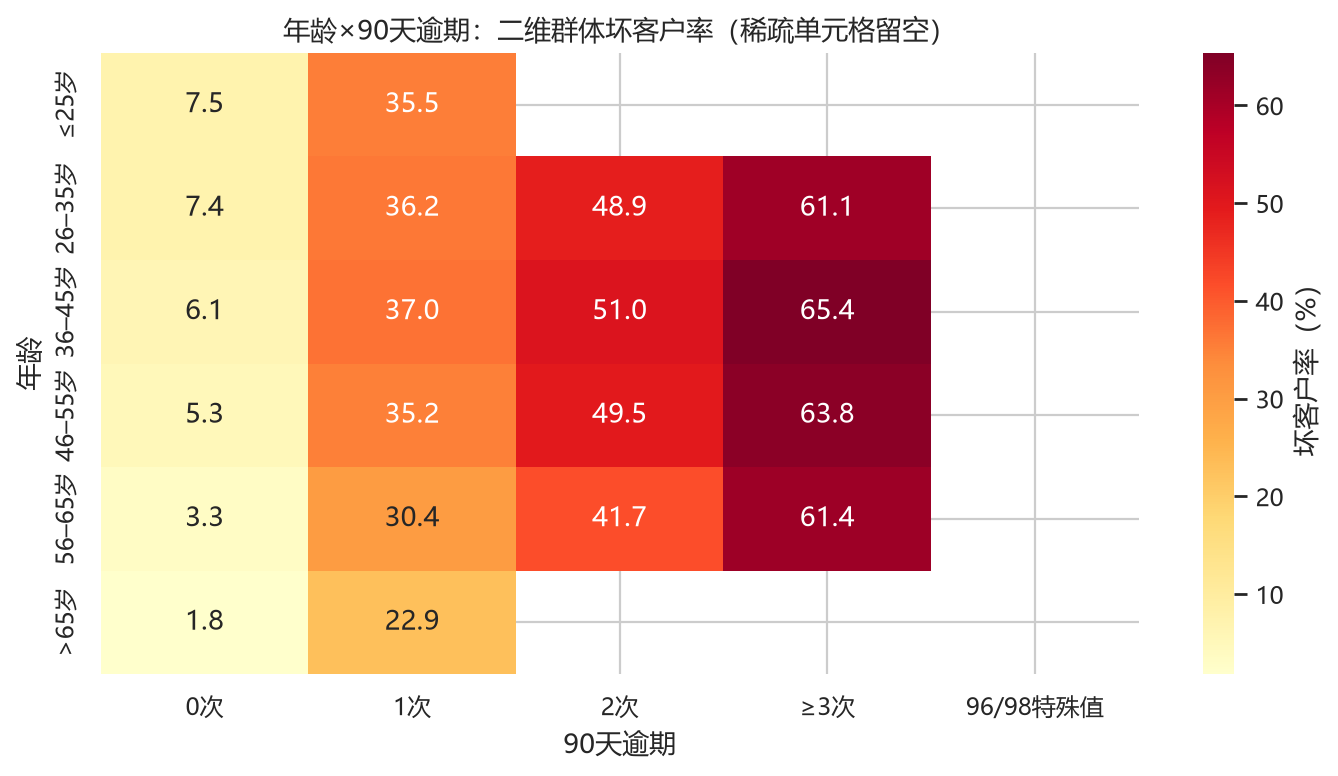

**统计结果：** 年龄×90天逾期中，稳定单元格最高坏率为65.35%（36–45岁 × ≥3次，n=254）；最低为1.82%（>65岁 × 0次，n=19,448）。

**风险含义：** 两个变量同时出现时，客户群体的观察风险可能不同。

**结论：** 可将差异作为后续特征工程的候选线索，而非直接入模结论。

**局限性：** 稀疏单元格不显示坏率；二维差异未控制其他变量，不能当作因果效应。

### 收入×债务比率

,group_a,group_b,sample_count,bad_count,bad_rate,unstable
0,"(-0.001, 3000.0]",0及以下,936,103,0.110043,False
1,"(-0.001, 3000.0]","(0,0.25]",6244,536,0.085842,False
2,"(-0.001, 3000.0]","(0.25,0.5]",3504,362,0.103311,False
3,"(-0.001, 3000.0]","(0.5,1]",3317,337,0.101598,False
4,"(-0.001, 3000.0]","(1,5]",2020,201,0.099505,False
5,"(-0.001, 3000.0]",>5,1611,65,0.040348,False
6,"(3000.0, 4516.4]",0及以下,354,28,0.079096,False
7,"(3000.0, 4516.4]","(0,0.25]",6425,499,0.077665,False
8,"(3000.0, 4516.4]","(0.25,0.5]",4960,384,0.077419,False
9,"(3000.0, 4516.4]","(0.5,1]",3649,357,0.097835,False


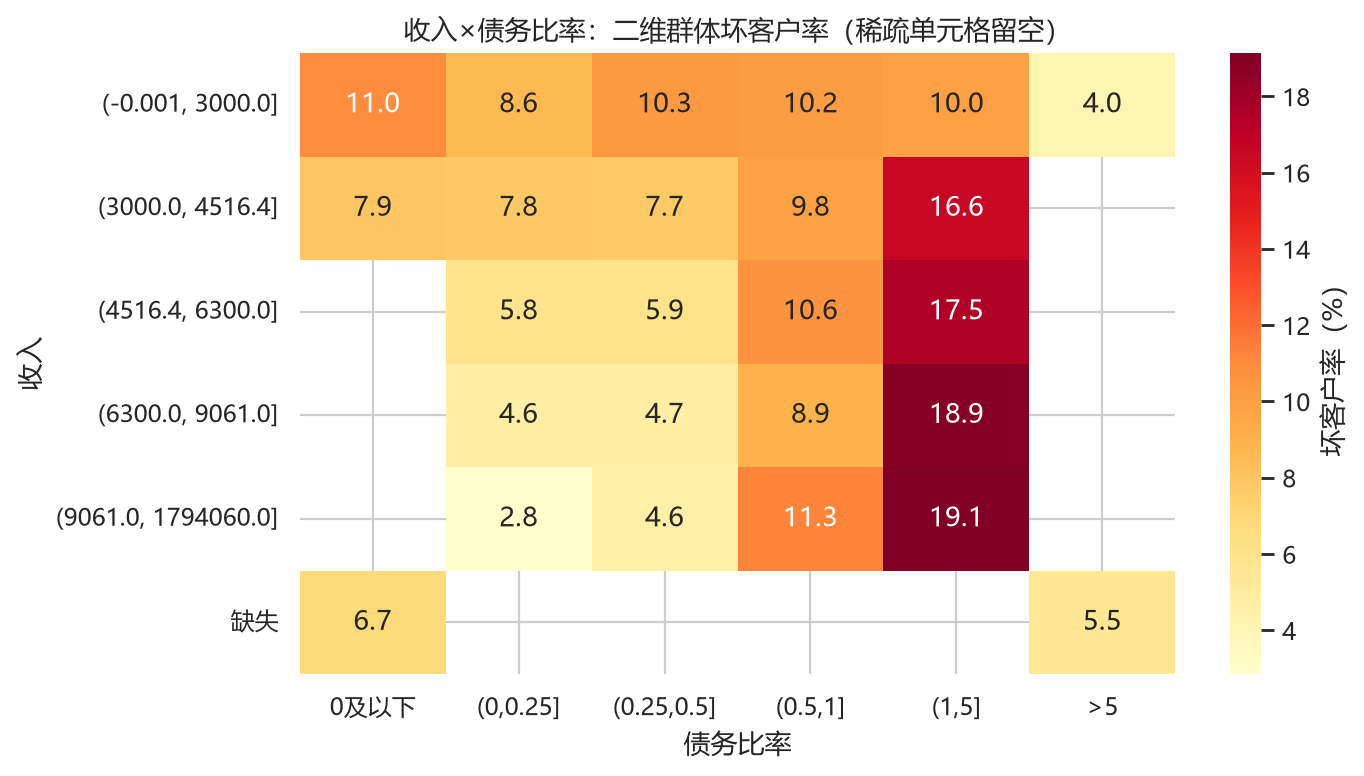

**统计结果：** 收入×债务比率中，稳定单元格最高坏率为19.13%（(9061.0, 1794060.0] × (1,5]，n=115）；最低为2.84%（(9061.0, 1794060.0] × (0,0.25]，n=7,983）。

**风险含义：** 两个变量同时出现时，客户群体的观察风险可能不同。

**结论：** 可将差异作为后续特征工程的候选线索，而非直接入模结论。

**局限性：** 稀疏单元格不显示坏率；二维差异未控制其他变量，不能当作因果效应。

### 额度使用率×30–59天逾期

,group_a,group_b,sample_count,bad_count,bad_rate,unstable
0,0及以下,0次,6935,134,0.019322,False
1,0及以下,1次,568,39,0.068662,False
2,0及以下,2次,118,22,0.186441,False
3,0及以下,≥3次,67,26,0.388060,True
4,"(0,0.3]",0次,51791,746,0.014404,False
5,"(0,0.3]",1次,4259,266,0.062456,False
6,"(0,0.3]",2次,828,113,0.136473,False
7,"(0,0.3]",≥3次,396,76,0.191919,False
8,"(0.3,0.7]",0次,15176,794,0.052319,False
9,"(0.3,0.7]",1次,2645,326,0.123251,False


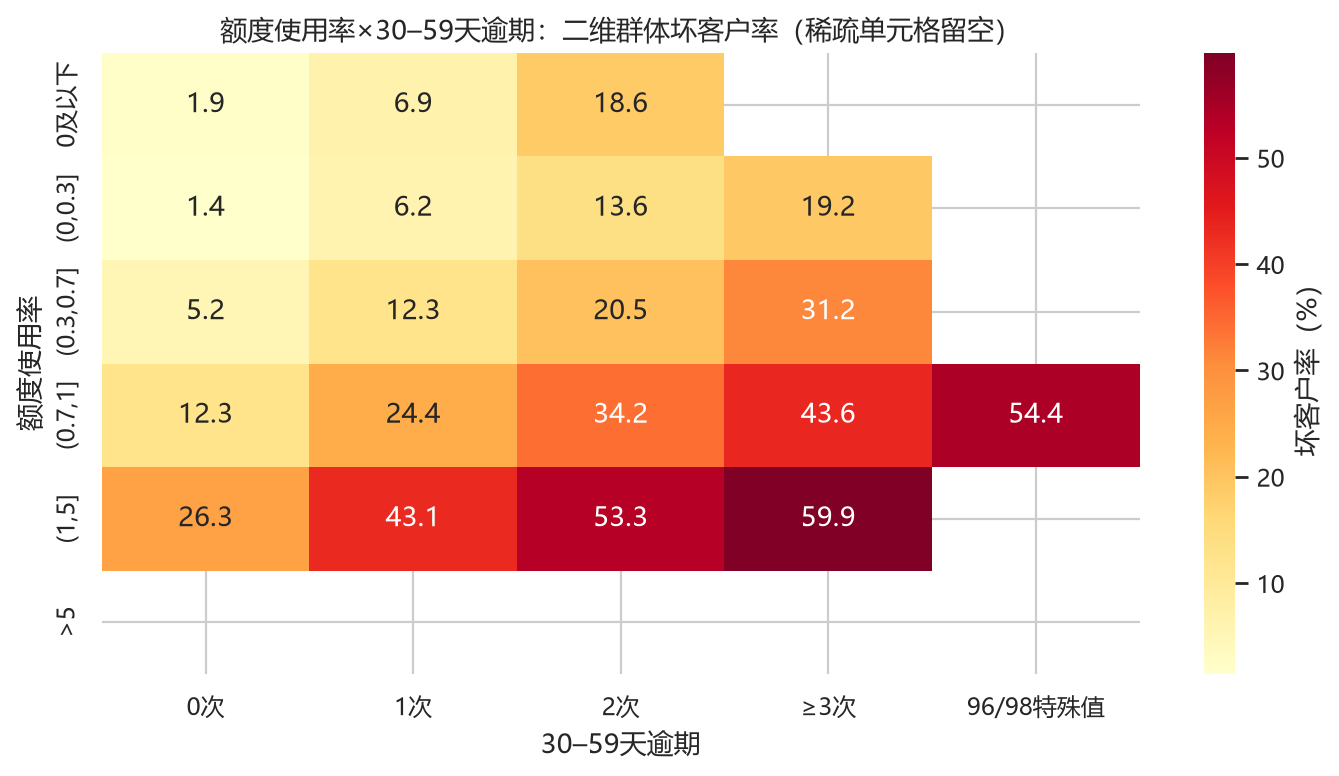

**统计结果：** 额度使用率×30–59天逾期中，稳定单元格最高坏率为59.86%（(1,5] × ≥3次，n=294）；最低为1.44%（(0,0.3] × 0次，n=51,791）。

**风险含义：** 两个变量同时出现时，客户群体的观察风险可能不同。

**结论：** 可将差异作为后续特征工程的候选线索，而非直接入模结论。

**局限性：** 稀疏单元格不显示坏率；二维差异未控制其他变量，不能当作因果效应。

,segment,sample_count,bad_count,sample_share,bad_rate,risk_lift
0,三类逾期均为0,83730,2301,0.797429,0.027481,0.411161
1,仅有30–59天逾期,12016,1403,0.114438,0.116761,1.746923
2,有60–89或90天逾期,9072,3215,0.086400,0.354387,5.302173
3,逾期特殊值,182,99,0.001733,0.543956,8.138413


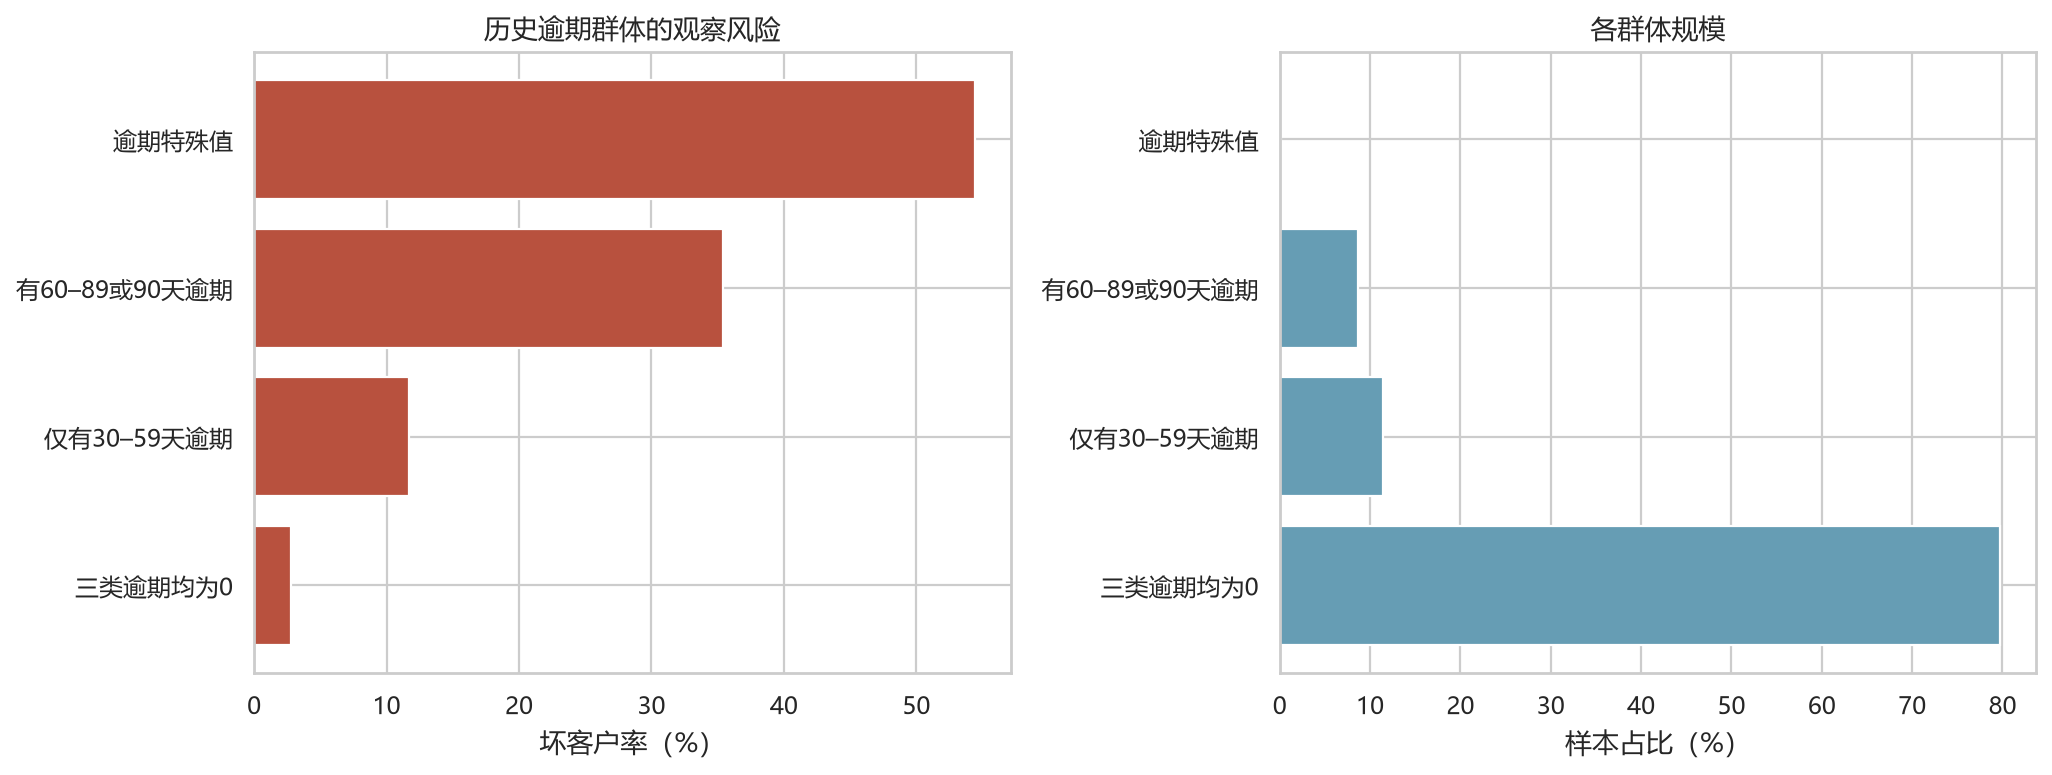

**统计结果：** “逾期特殊值”群体坏率最高，为54.40%，样本数182；训练集整体坏率6.68%。

**风险含义：** 历史逾期状态可帮助描述不同客户群体的风险差异。

**结论：** 该群体划分只用于EDA，不构成最终评分等级或审批策略。

**局限性：** 分组未控制收入、年龄等共同影响因素，不能直接推断个体风险。

In [4]:
show_chart('correlation')
for index, (name, table) in enumerate(eda.interactions.items(), start=1):
    display(Markdown(f'### {name}'))
    display(table)
    show_chart(f'interaction_{index}')
display(eda.risk_segments)
show_chart('risk_segments')

## 四、初步区分能力

单变量 AUC 与 KS 只在训练集上计算，特殊逾期值和缺失值在对应字段计算时排除。AUC 按风险方向校正，仅供确定后续分析重点。正式 IV、变量筛选和模型验证属于后续阶段。

,feature,valid_count,excluded_count,single_auc,single_ks,direction,limitation
0,RevolvingUtilizationOfUnsecuredLines,105000,0,0.777889,0.461167,值越大风险越高,仅训练集原始单变量探索；缺失/特殊值单独排除；不等同于入模效果
2,NumberOfTime30-59DaysPastDueNotWorse,104818,182,0.683107,0.349815,值越大风险越高,仅训练集原始单变量探索；缺失/特殊值单独排除；不等同于入模效果
6,NumberOfTimes90DaysLate,104818,182,0.654772,0.306974,值越大风险越高,仅训练集原始单变量探索；缺失/特殊值单独排除；不等同于入模效果
1,age,105000,0,0.630791,0.198691,值越小风险越高,仅训练集原始单变量探索；缺失/特殊值单独排除；不等同于入模效果
8,NumberOfTime60-89DaysPastDueNotWorse,104818,182,0.617310,0.233146,值越大风险越高,仅训练集原始单变量探索；缺失/特殊值单独排除；不等同于入模效果
4,MonthlyIncome,84277,20723,0.574889,0.125795,值越小风险越高,仅训练集原始单变量探索；缺失/特殊值单独排除；不等同于入模效果
5,NumberOfOpenCreditLinesAndLoans,105000,0,0.546472,0.095797,值越小风险越高,仅训练集原始单变量探索；缺失/特殊值单独排除；不等同于入模效果
9,NumberOfDependents,102279,2721,0.545489,0.081300,值越大风险越高,仅训练集原始单变量探索；缺失/特殊值单独排除；不等同于入模效果
7,NumberRealEstateLoansOrLines,105000,0,0.535974,0.097026,值越小风险越高,仅训练集原始单变量探索；缺失/特殊值单独排除；不等同于入模效果
3,DebtRatio,105000,0,0.522722,0.069652,值越大风险越高,仅训练集原始单变量探索；缺失/特殊值单独排除；不等同于入模效果


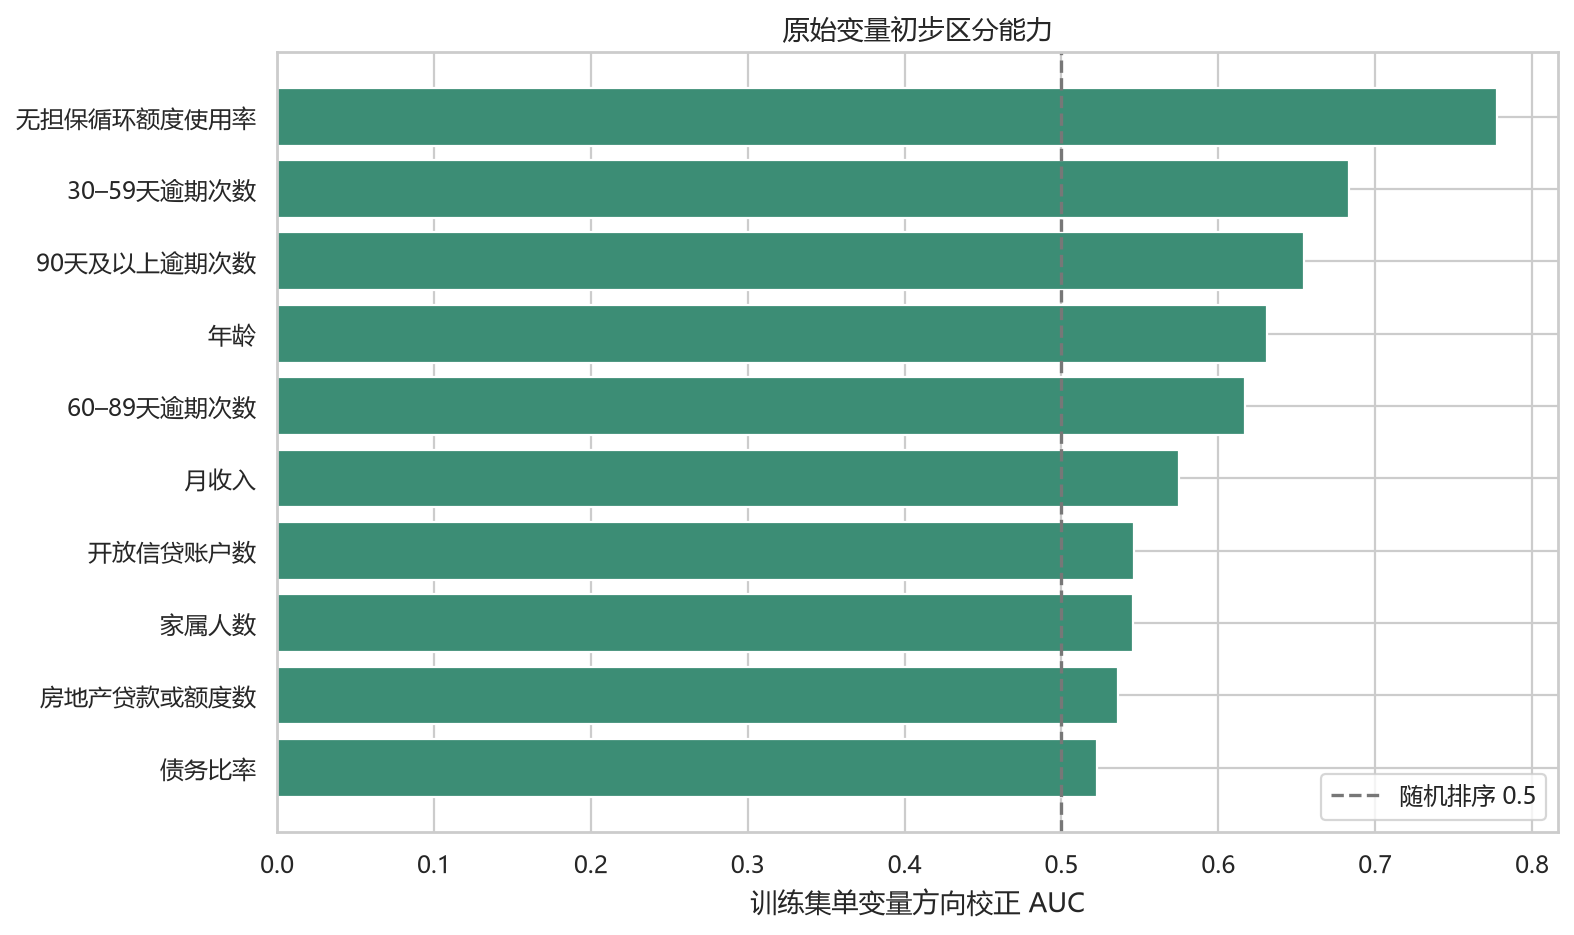

**统计结果：** 训练集原始单变量方向校正AUC最高的是无担保循环额度使用率：0.778；对应KS为0.461。

**风险含义：** 单变量排序指标可提示初步风险区分能力。

**结论：** 此排名仅用于确定后续分析重点，不在第二阶段筛选变量。

**局限性：** 统计来自同一训练集，未做验证；非单调关系、缺失与特殊值会影响指标，不能替代第三阶段IV分析或模型验证。

In [5]:
display(eda.discrimination)
show_chart('single_feature_discrimination')

## 本阶段结论边界

所有结论是训练集的观察结果，不代表因果关系或真实授信决策。验证集仅用于后续模型选择；划分出的测试集留待最终一次评价。